# Carga del dataset y librerias

## Importación de librerias

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import time
from sklearn.metrics import confusion_matrix, accuracy_score, ConfusionMatrixDisplay, balanced_accuracy_score, classification_report
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler
from sklearn.model_selection import train_test_split, PredefinedSplit, GridSearchCV
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB, ComplementNB
from scipy.signal import butter, filtfilt, find_peaks
from scipy.stats import skew, kurtosis

## Lectura del dataset

In [2]:
df_trainval = pd.read_csv('df_smartphone_trainval.csv')
df_test = pd.read_csv('df_smartphone_test.csv')

In [3]:
grouped_trainval = df_trainval.groupby('person_id')
groups = [group for _,group in grouped_trainval]
train_groups, val_groups = train_test_split(groups, test_size=0.2, random_state=3)

df_train = pd.concat(train_groups)
df_val = pd.concat(val_groups)

X_train = df_train.drop(columns=['class'])
y_train = df_train['class']
X_val = df_val.drop(columns=['class'])
y_val = df_val['class']

# Gráficos de las señales

In [6]:
def graphs(i, df):
  samples = np.arange(0, 125, 1)

  def maker(IMU):
    X_features = [col for col in df.columns if col.startswith(f'{IMU}x')]
    Y_features = [col for col in df.columns if col.startswith(f'{IMU}y')]
    Z_features = [col for col in df.columns if col.startswith(f'{IMU}z')]
    i_row_IMUx = df[X_features].iloc[i]
    i_row_IMUy = df[Y_features].iloc[i]
    i_row_IMUz = df[Z_features].iloc[i]

    plt.figure(figsize=(12, 6))
    plt.plot(samples, i_row_IMUx)
    plt.plot(samples, i_row_IMUy)
    plt.plot(samples, i_row_IMUz)
    plt.title(f'Lecturas del {IMU}')
    plt.xlabel('Muestras')
    plt.ylabel('Valor')
    plt.legend([f'x',f'y',f'z'], loc='upper right')
    plt.grid(True)
    plt.show()

  maker('ac')
  print('\n')
  maker('gy')
  print('\n')
  maker('ma')

Lecturas clase 1


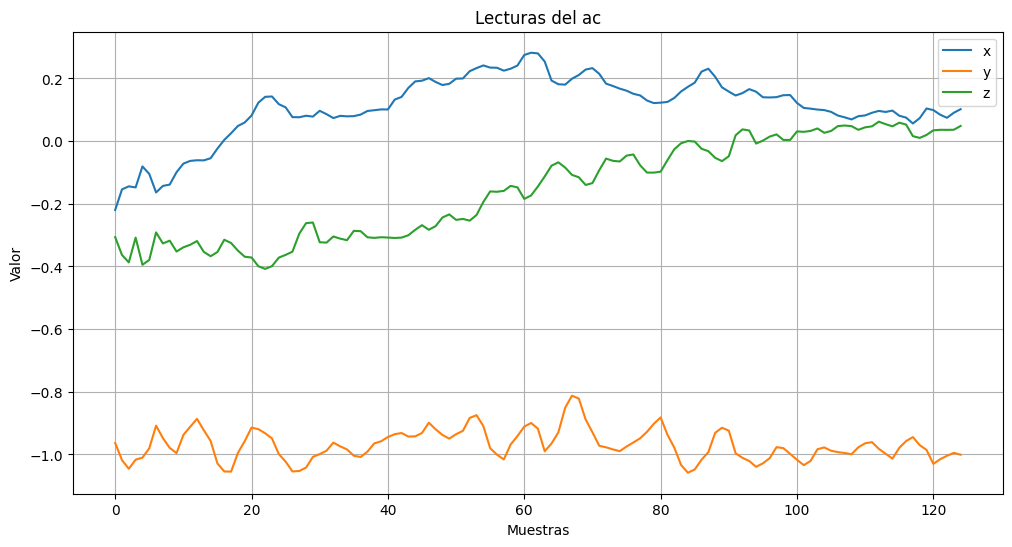

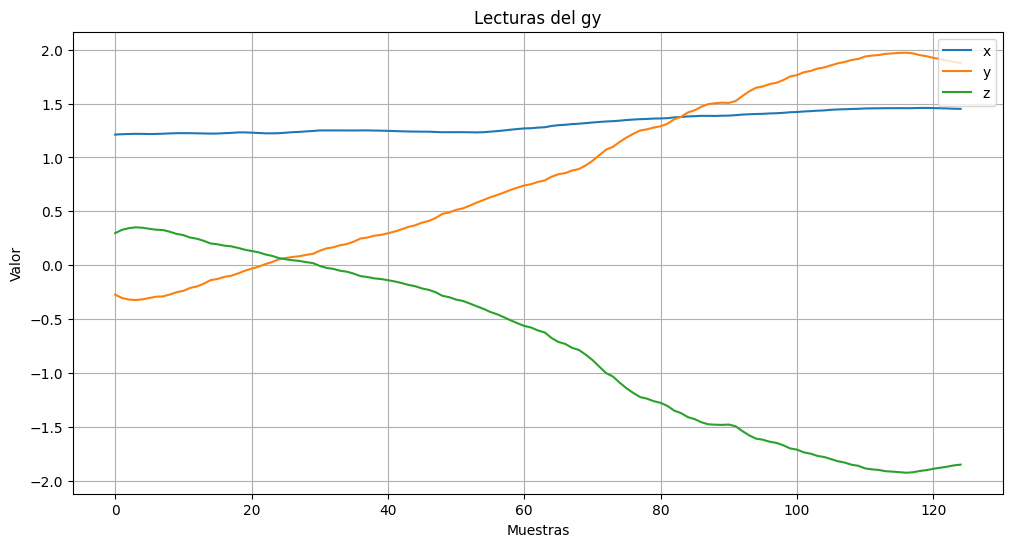

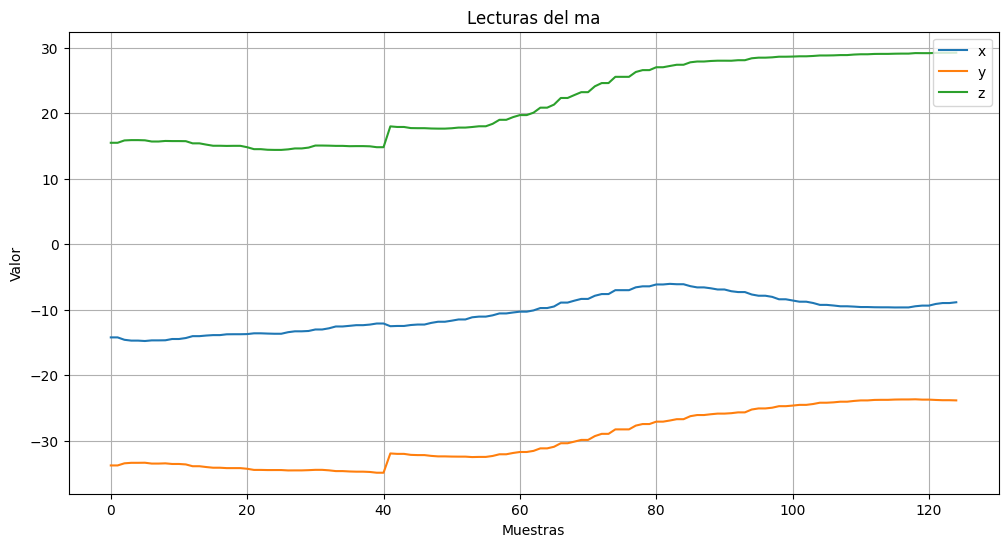



Lecturas clase 2


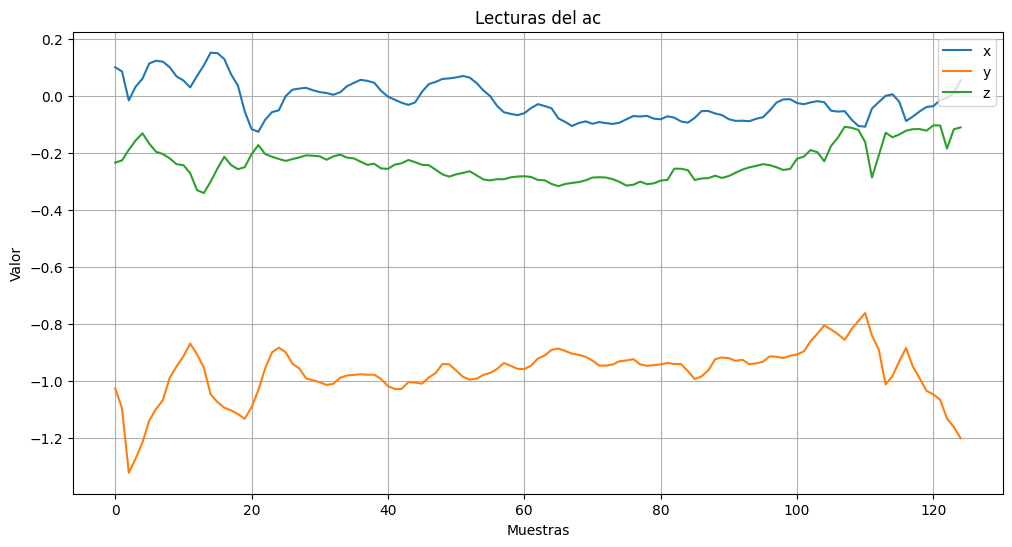

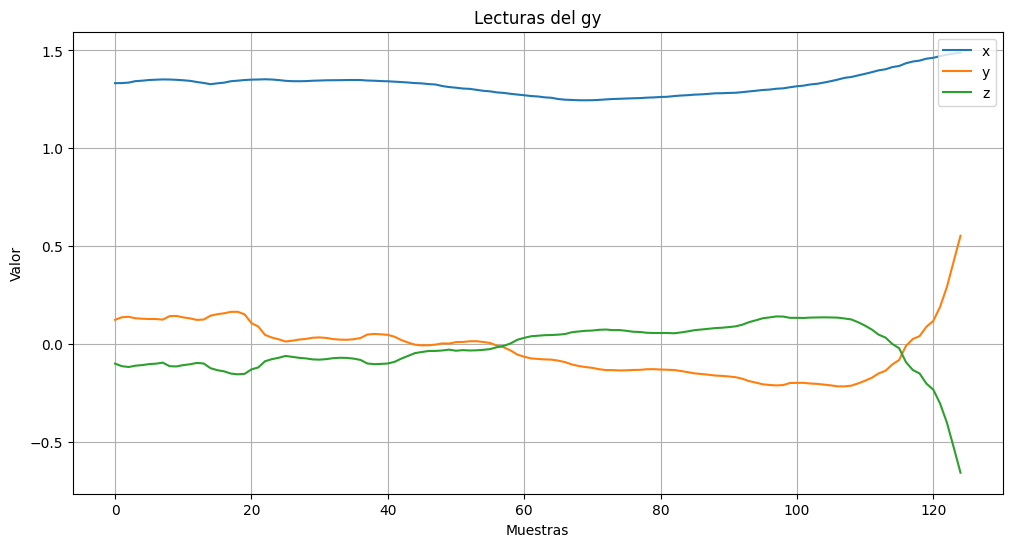

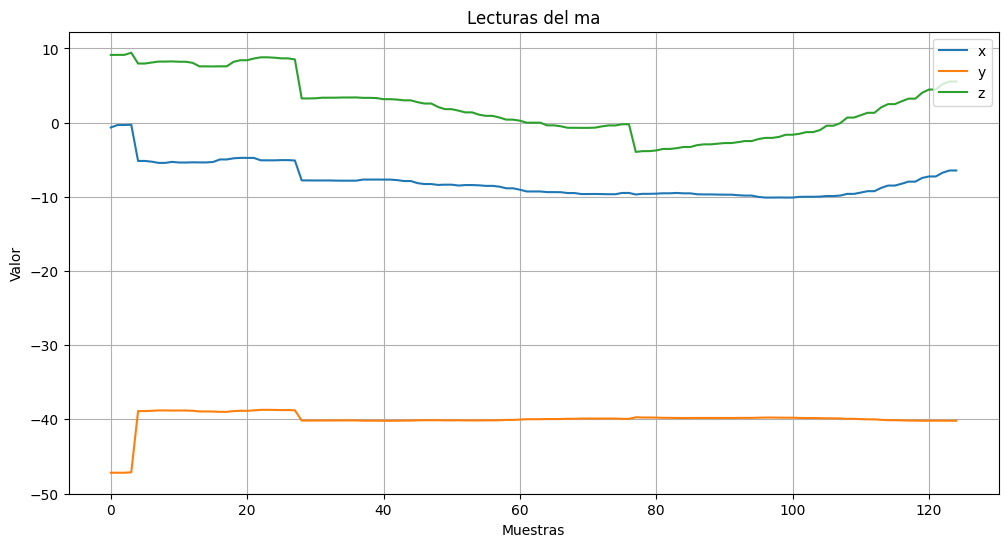



Lecturas clase 3


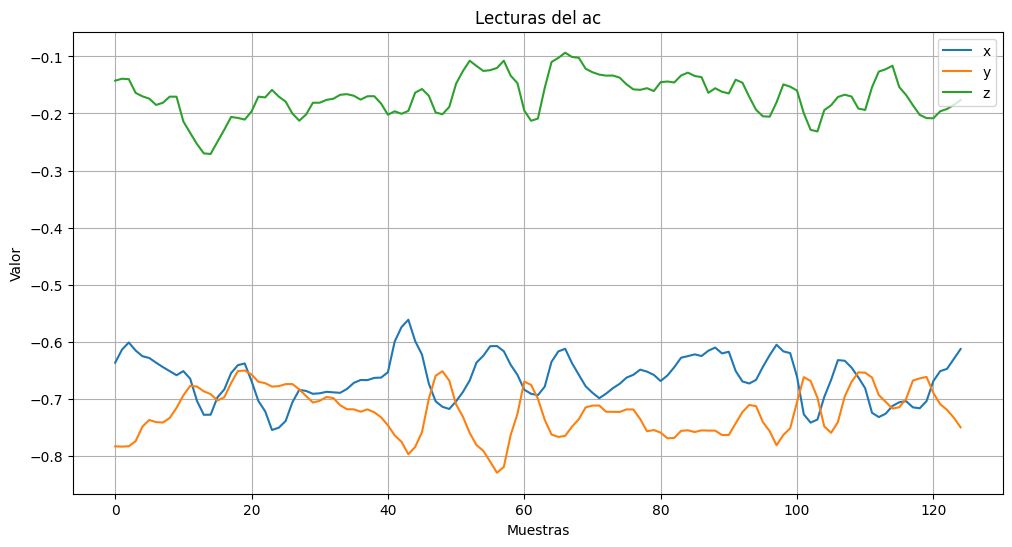

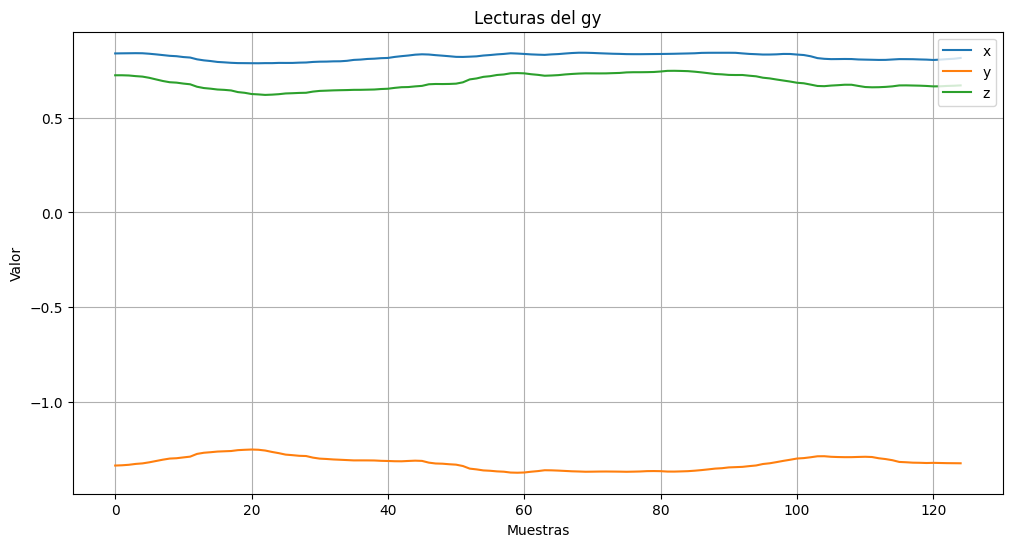

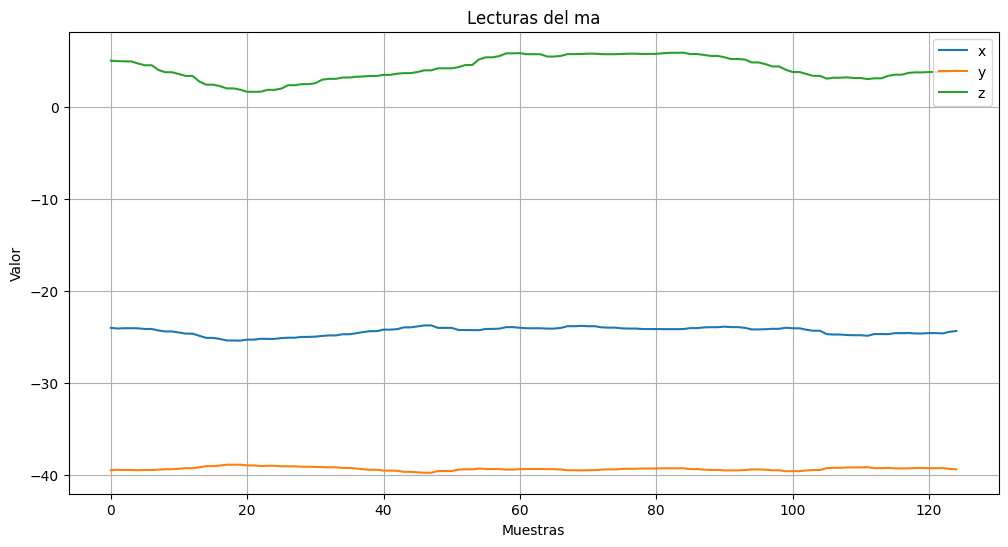



Lecturas clase 4


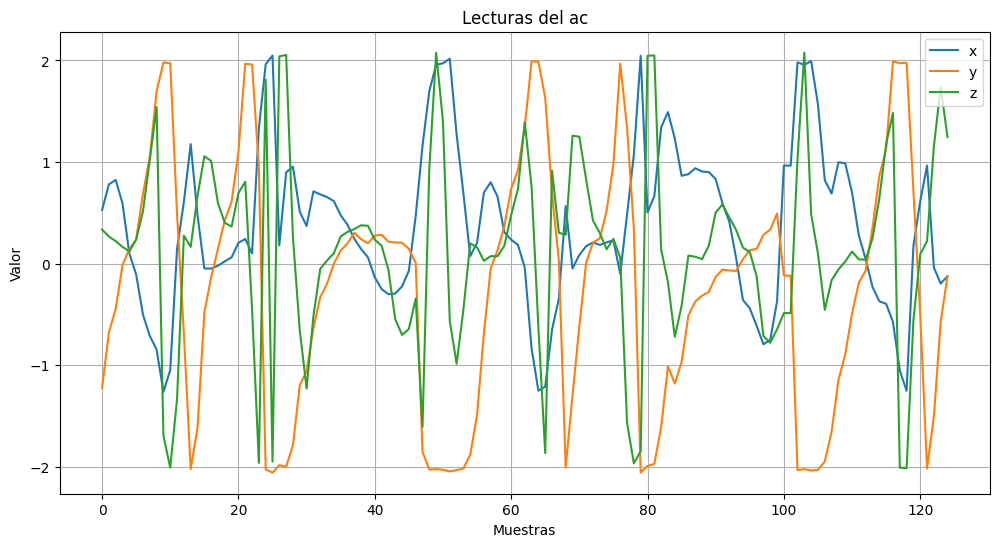

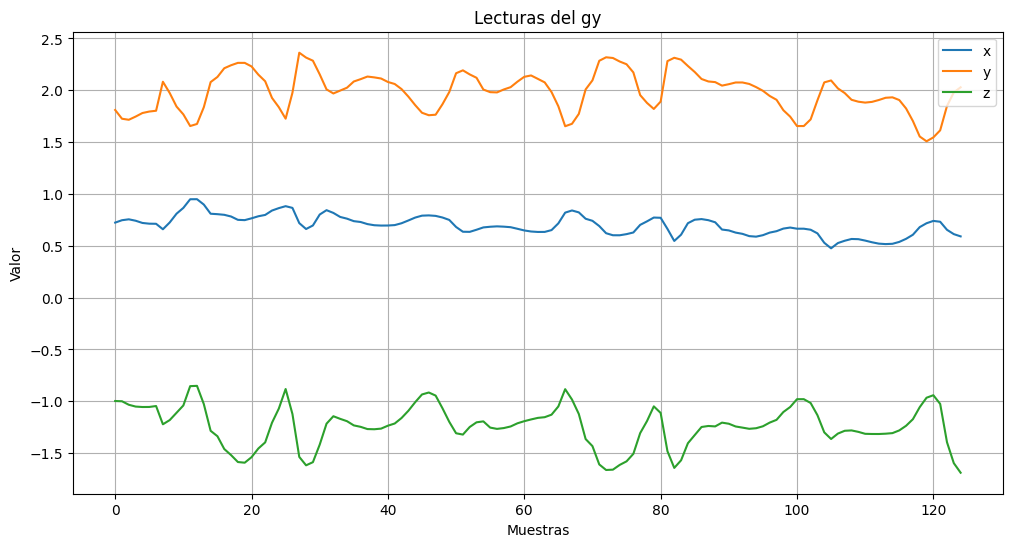

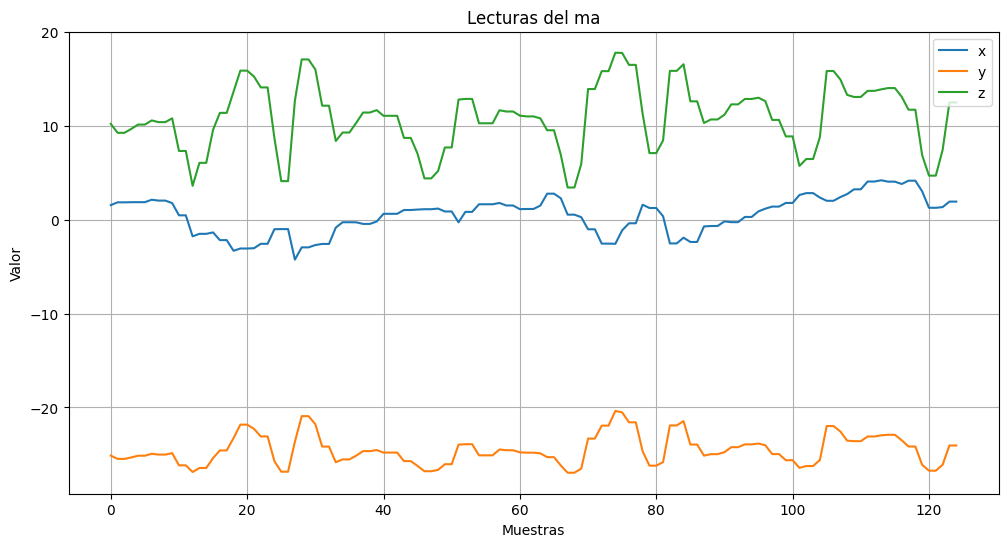



Lecturas clase 5


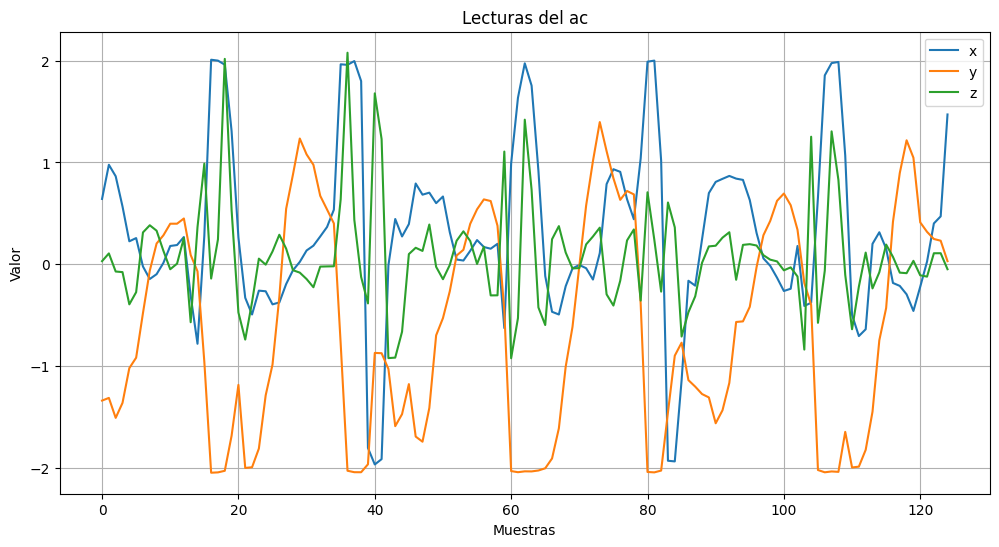

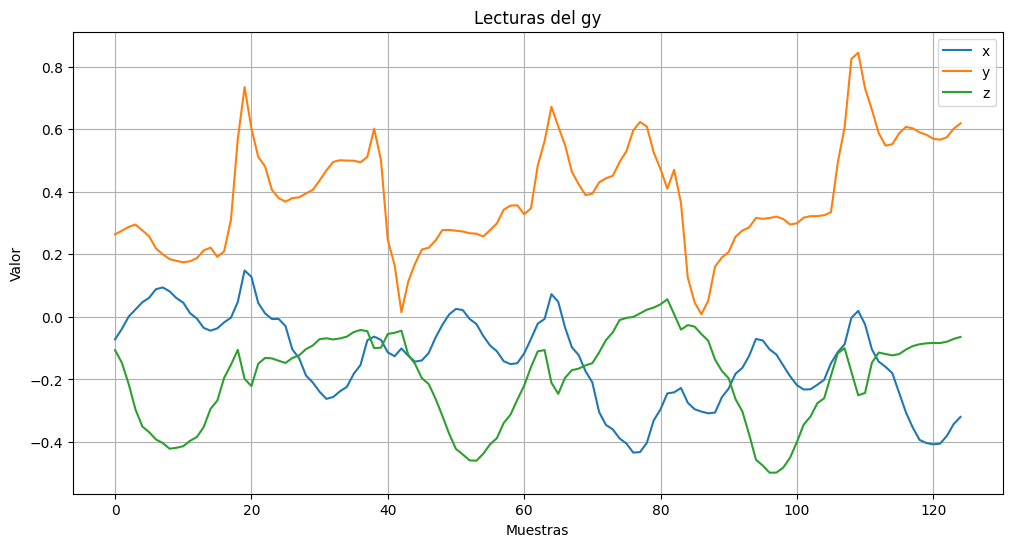

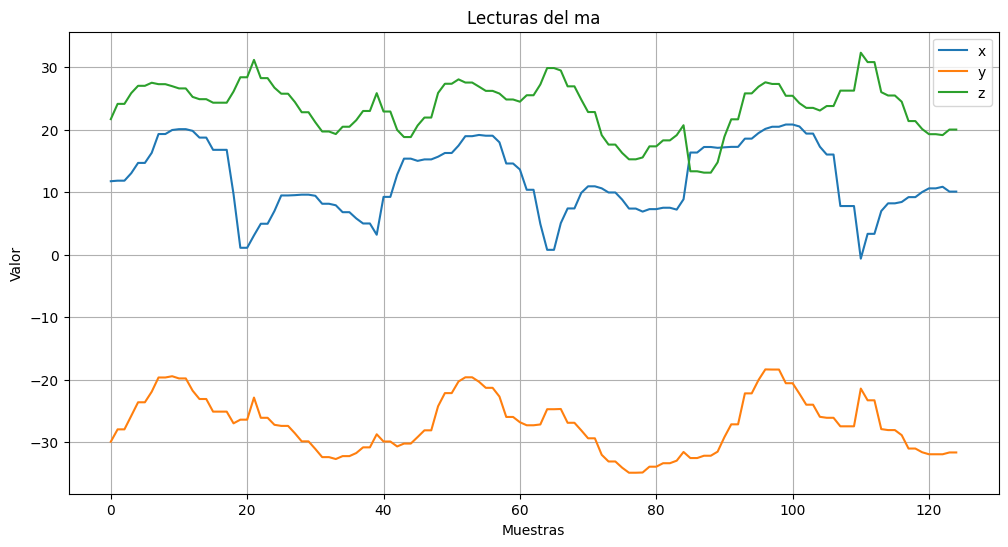



Lecturas clase 6


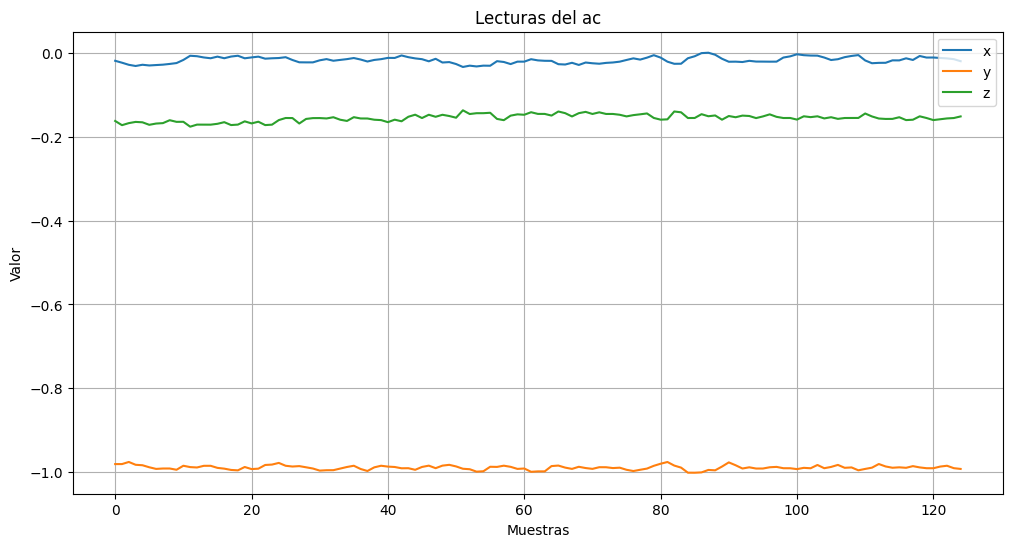

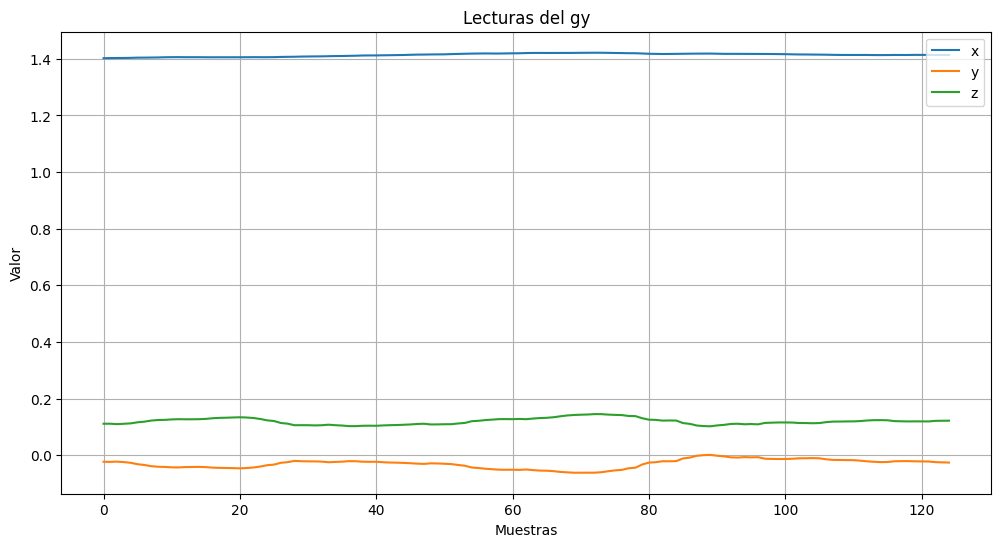

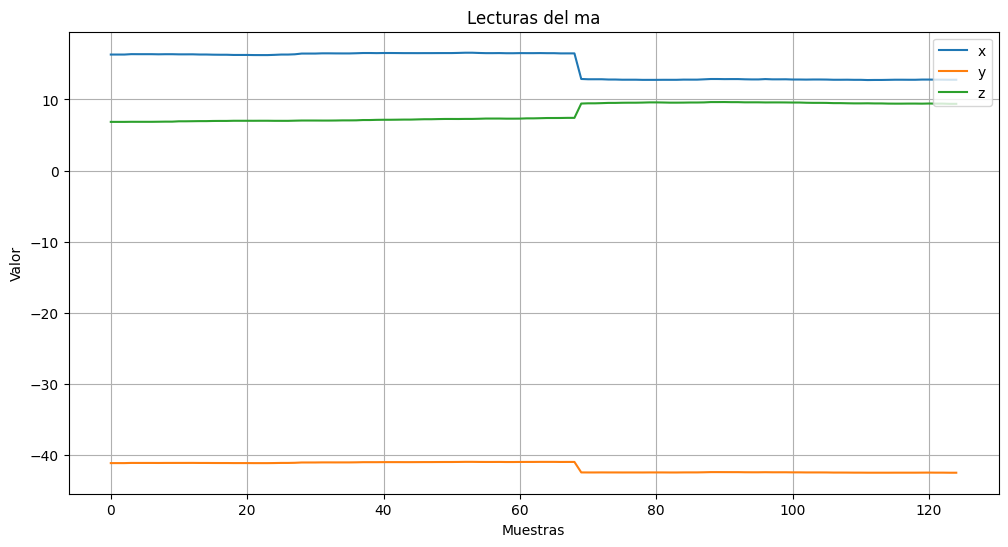



Lecturas clase 7


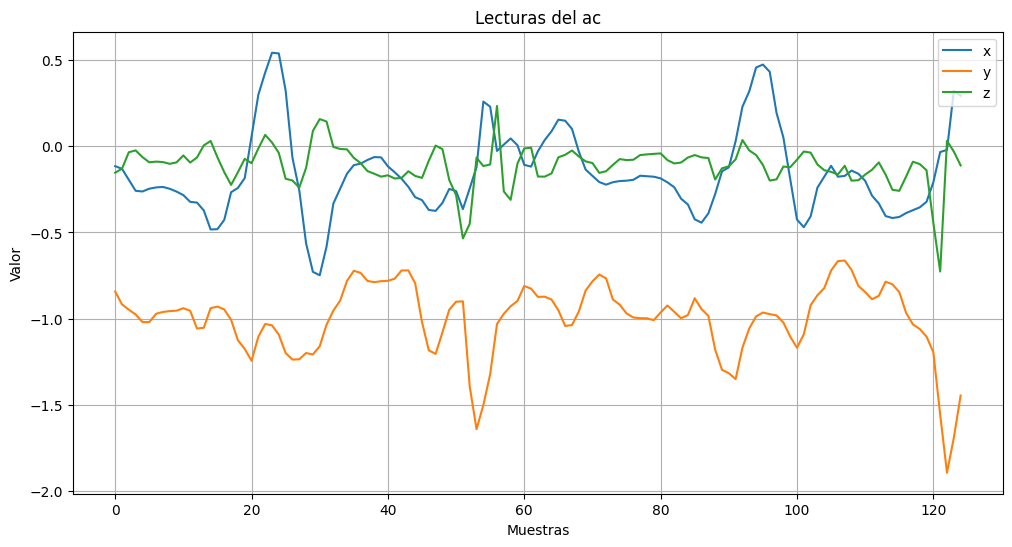

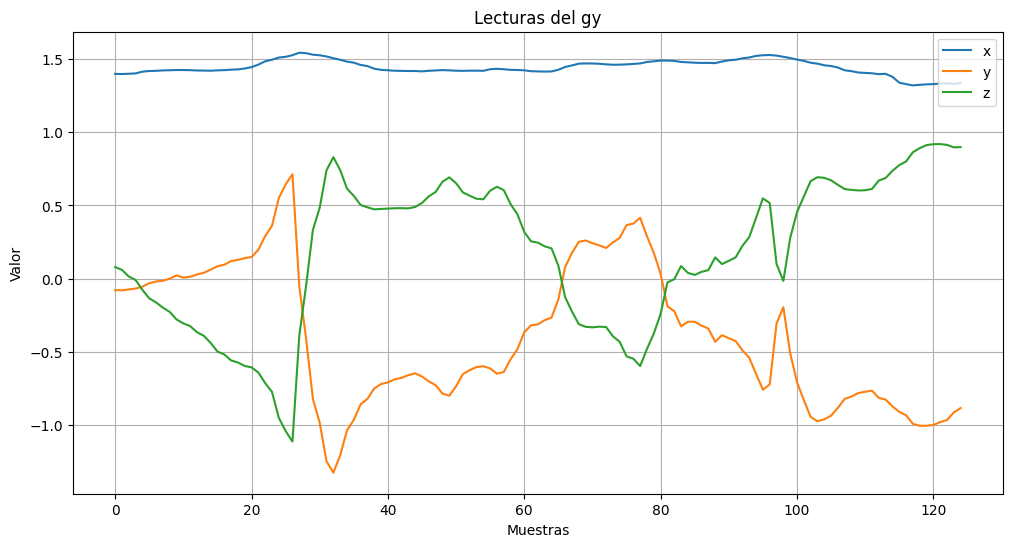

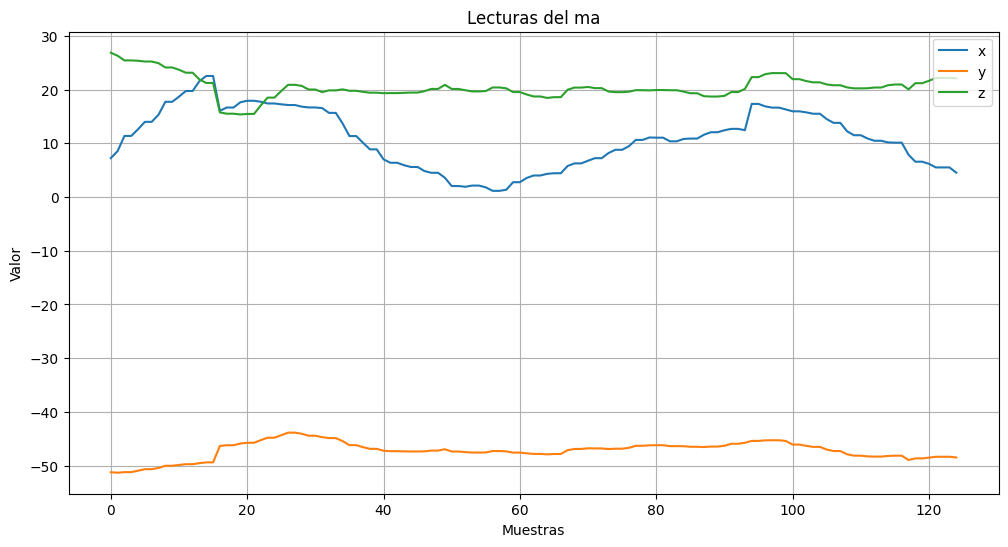



Lecturas clase 8


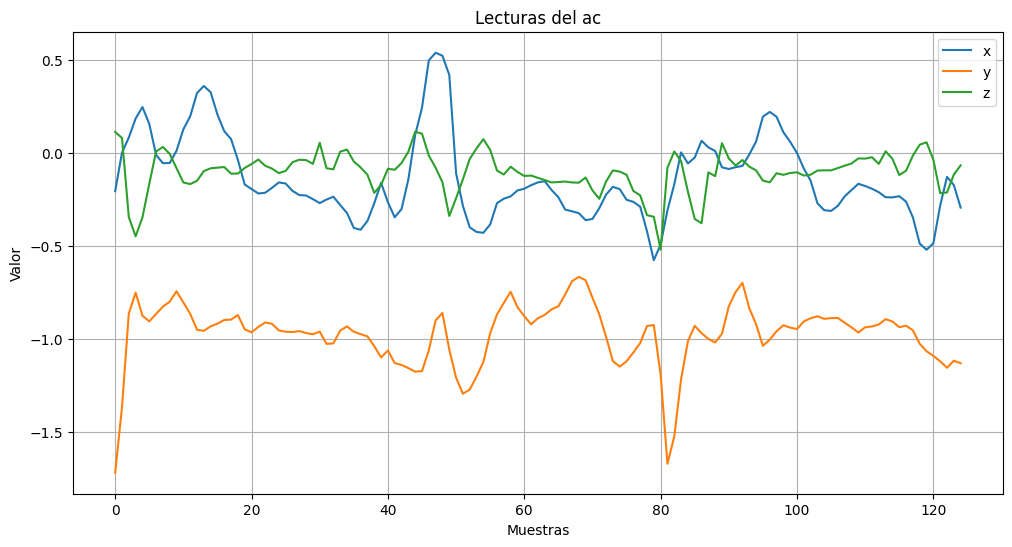

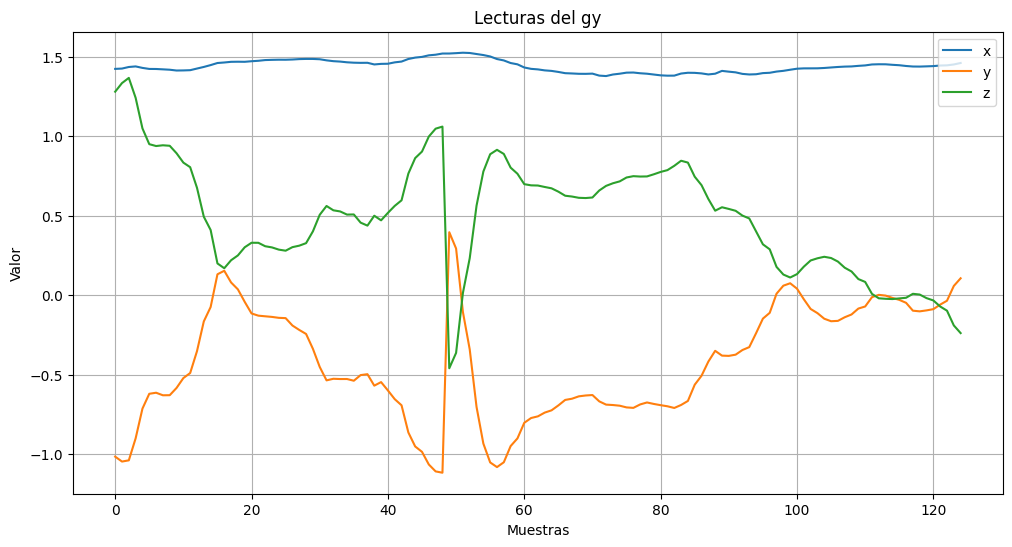

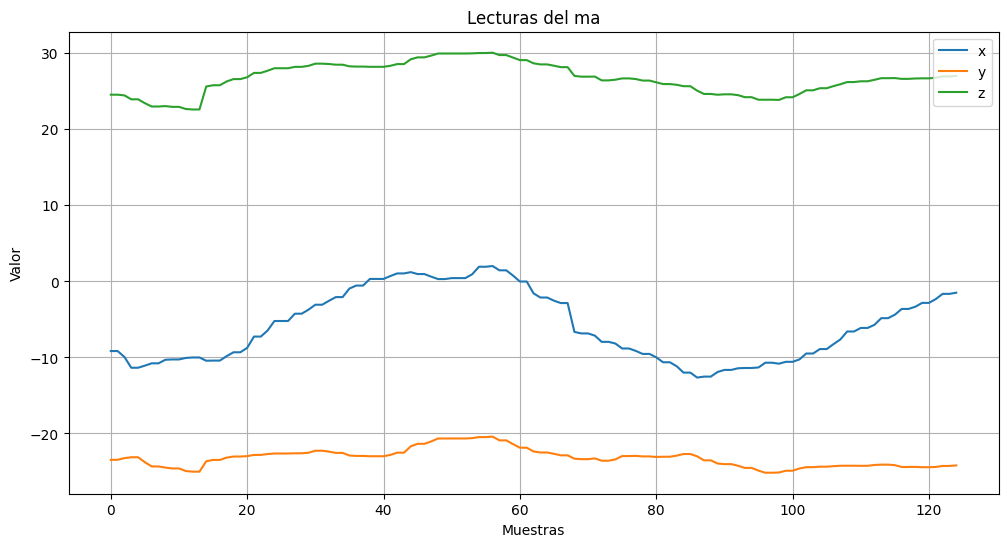

In [7]:
first_class_occurrences = df_trainval.drop_duplicates(subset='class', keep='first')
for i in range(0,len(first_class_occurrences)):
  print(f'Lecturas clase {i+1}')
  graphs(i, first_class_occurrences)
  print('\n')

In [8]:
def graphs_2(df,axis):
  samples = np.arange(0, 125, 1)
  ac = []
  gy = []
  ma = []
  ac_features = [col for col in df.columns if col.startswith(f'ac{axis}')]
  gy_features = [col for col in df.columns if col.startswith(f'gy{axis}')]
  ma_features = [col for col in df.columns if col.startswith(f'ma{axis}')]

  for n in range(0, len(df)):
    n_row_ac = df[ac_features].iloc[n].tolist()
    ac.append(n_row_ac)
    n_row_gy = df[gy_features].iloc[n].tolist()
    gy.append(n_row_gy)
    n_row_ma = df[ma_features].iloc[n].tolist()
    ma.append(n_row_ma)

  print('\n')
  plt.figure(figsize=(12, 6))
  for i in range(8):
      plt.plot(samples, ac[i], label=f'clase {i}')
  plt.title(f'Lecturas del ac_{axis}')
  plt.xlabel('Muestras')
  plt.ylabel('Valor')
  plt.legend(loc='upper right')
  plt.grid(True)
  plt.show()
  print('\n')
  plt.figure(figsize=(12, 6))
  for i in range(8):
      plt.plot(samples, gy[i], label=f'clase {i}')
  plt.title(f'Lecturas del gy_{axis}')
  plt.xlabel('Muestras')
  plt.ylabel('Valor')
  plt.legend(loc='upper right')
  plt.grid(True)
  plt.show()
  print('\n')
  plt.figure(figsize=(12, 6))
  for i in range(8):
      plt.plot(samples, ma[i], label=f'clase {i}')
  plt.title(f'Lecturas del ma_{axis}')
  plt.xlabel('Muestras')
  plt.ylabel('Valor')
  plt.legend(loc='upper right')
  plt.grid(True)
  plt.show()

Gráficos según clases




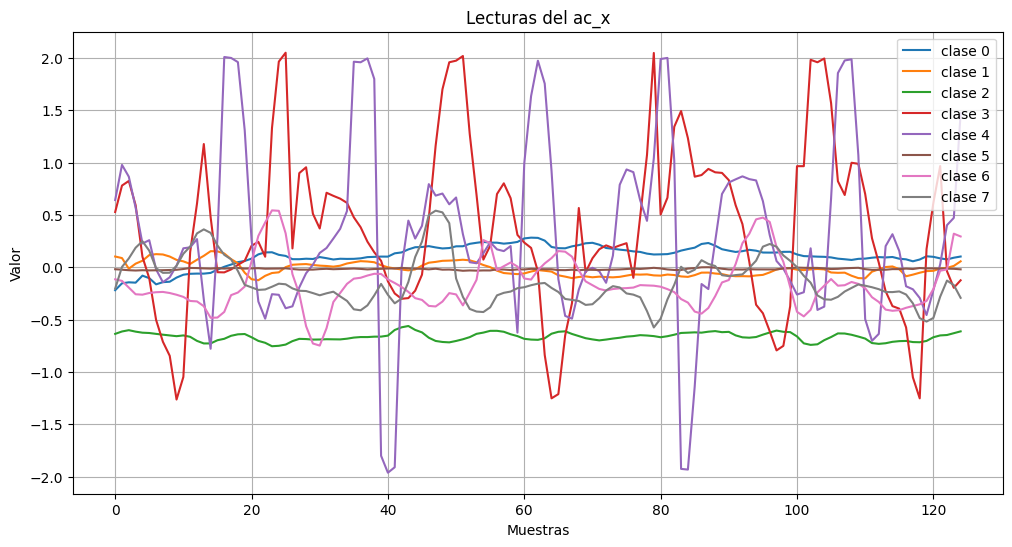

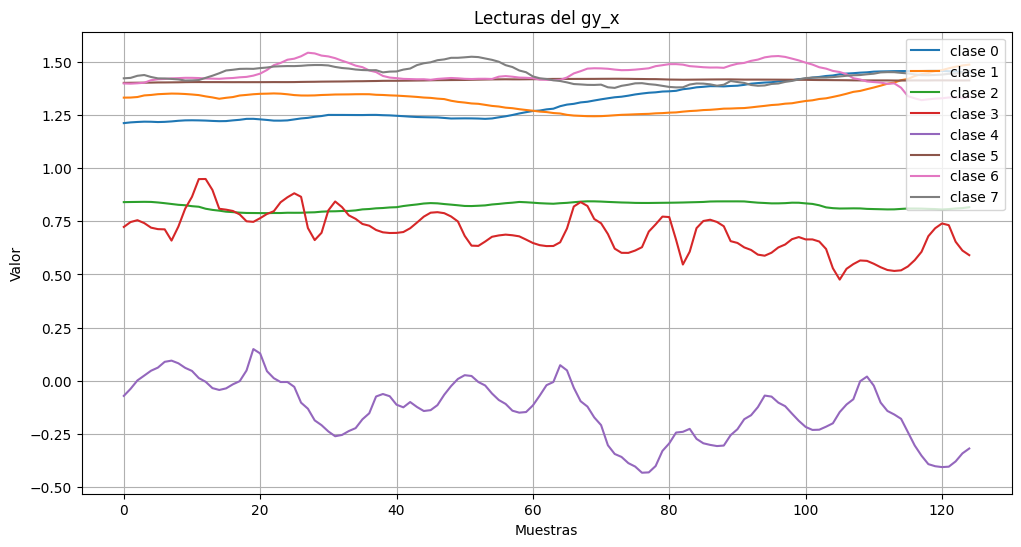

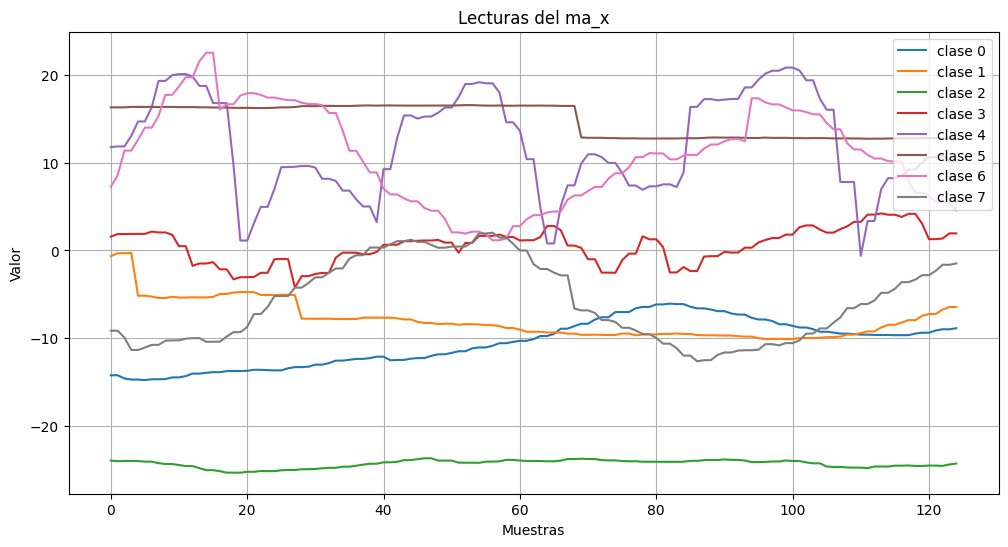

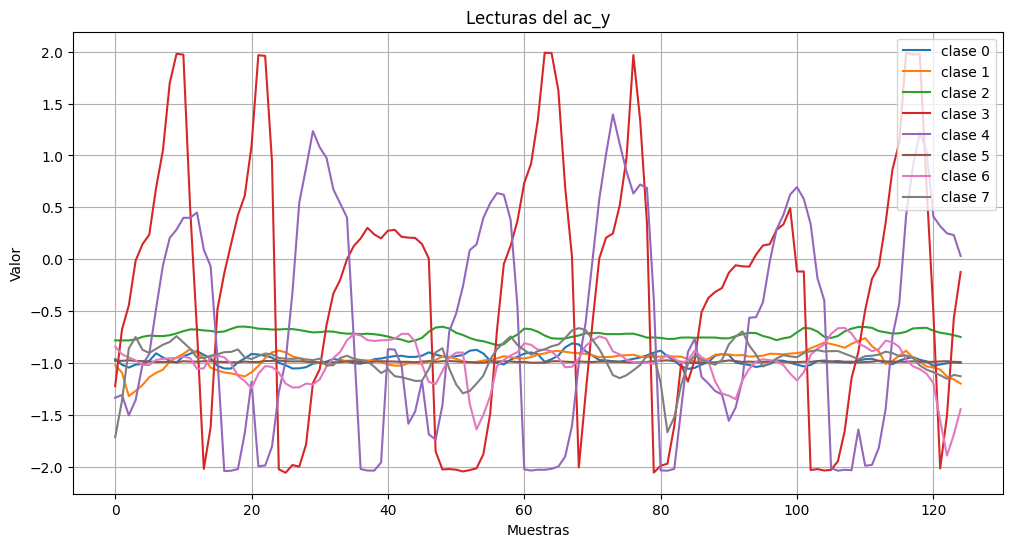

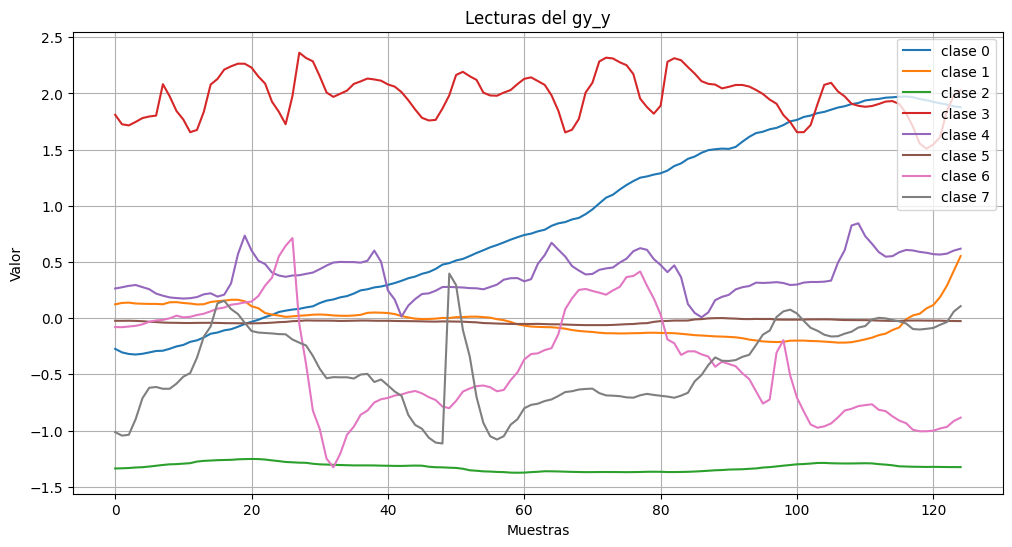

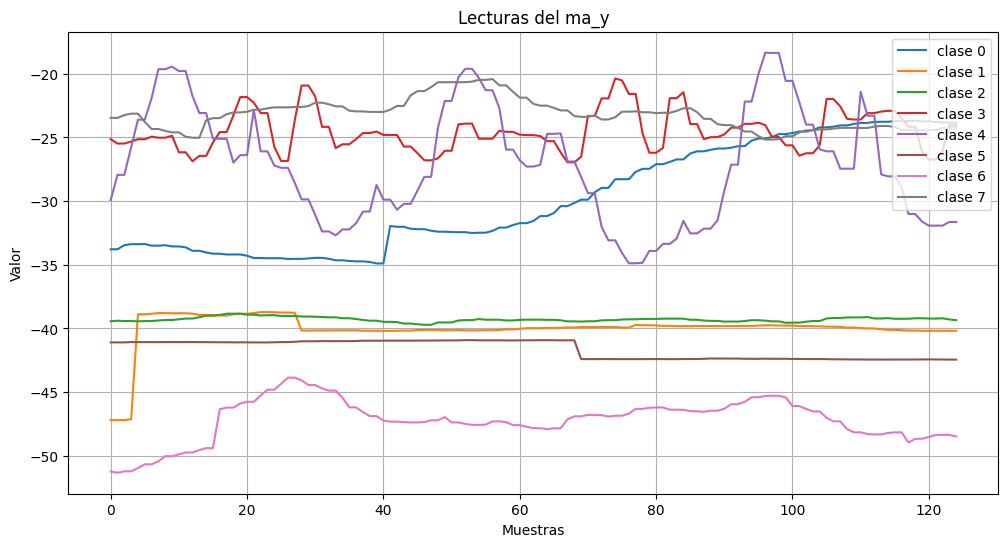

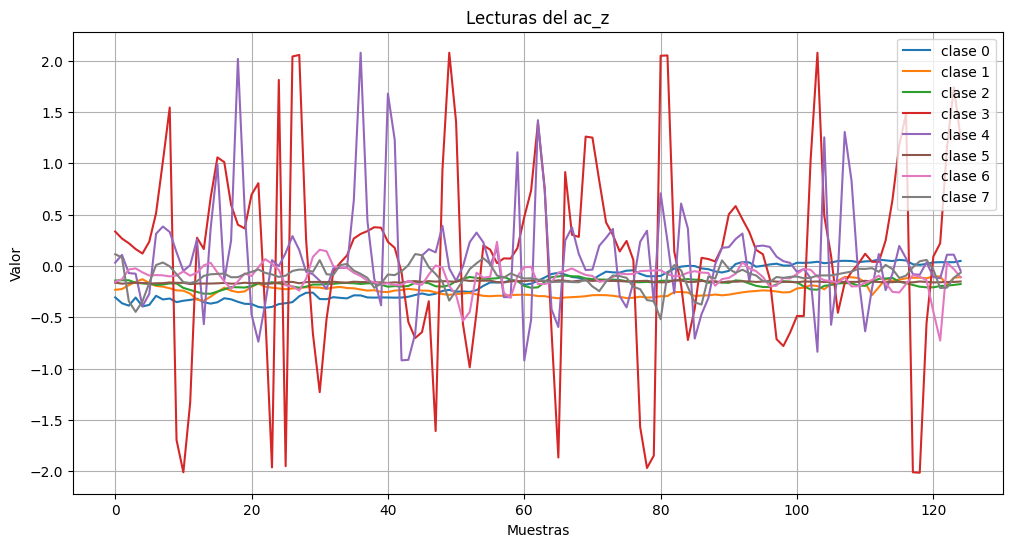

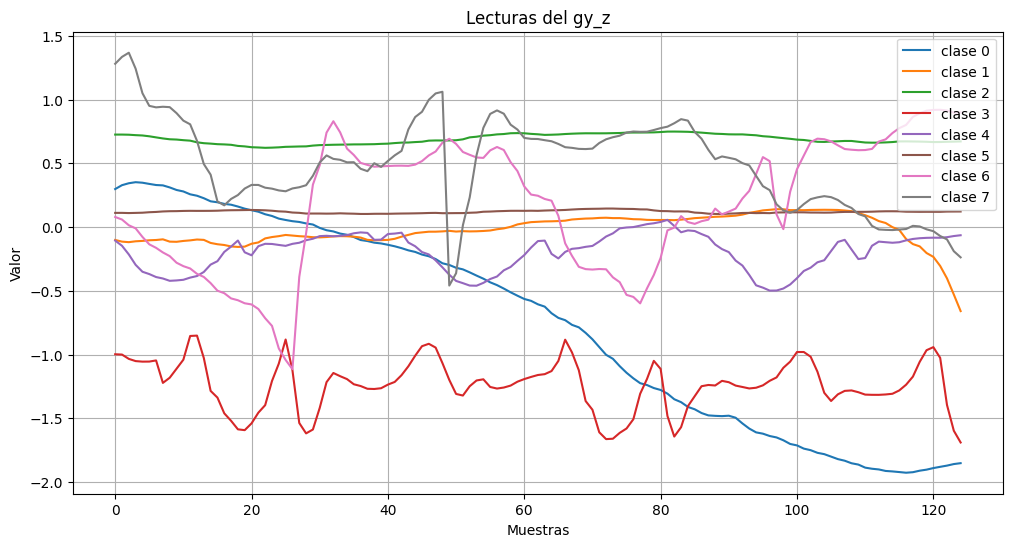

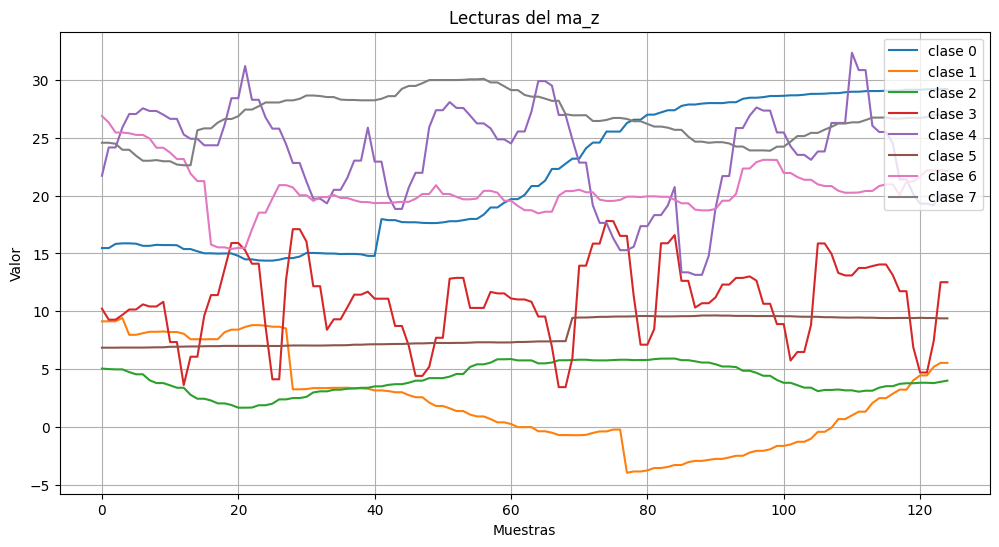

In [9]:
print('Gráficos según clases')
graphs_2(first_class_occurrences, 'x')
graphs_2(first_class_occurrences, 'y')
graphs_2(first_class_occurrences, 'z')

# Eliminación de señales


No se eliminara ninguna señal, pues en vista de los graficos anteriores es claro que los patrones de las señales de los sensores en los tres ejes son unicos para la mayoria de las clases, por lo que eliminar alguna señal podria ser perjudicial para el desarrollo de los clasificadores.

# Filtrado de señales

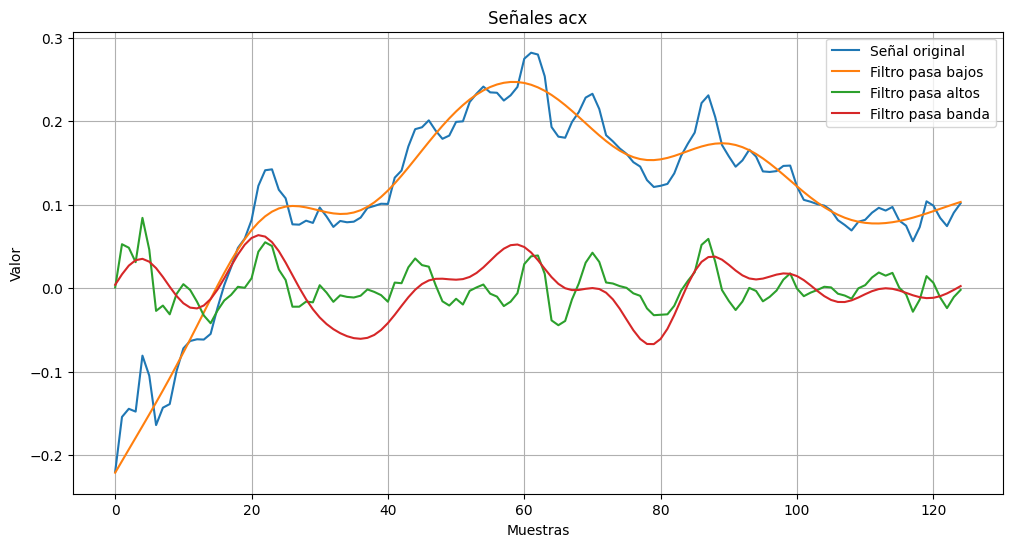

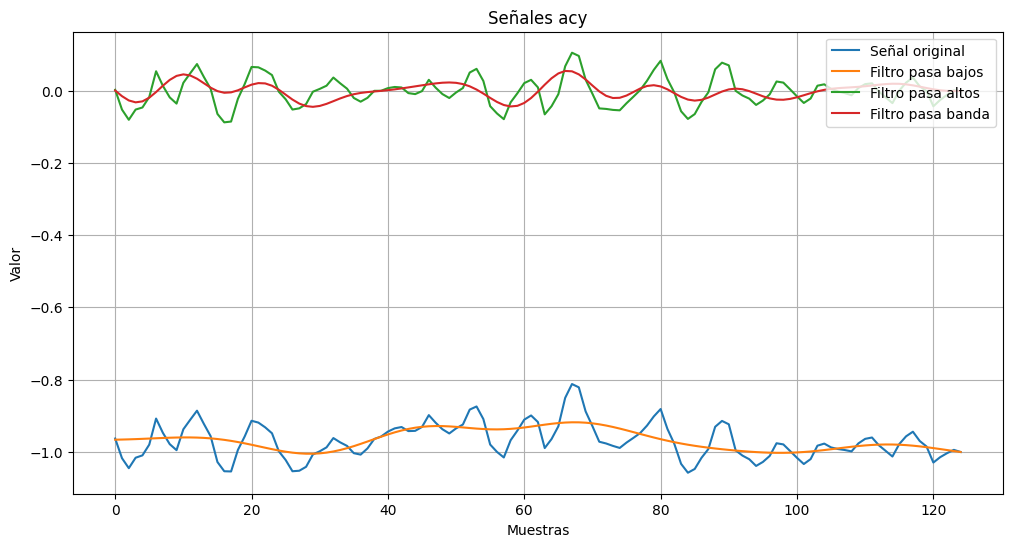

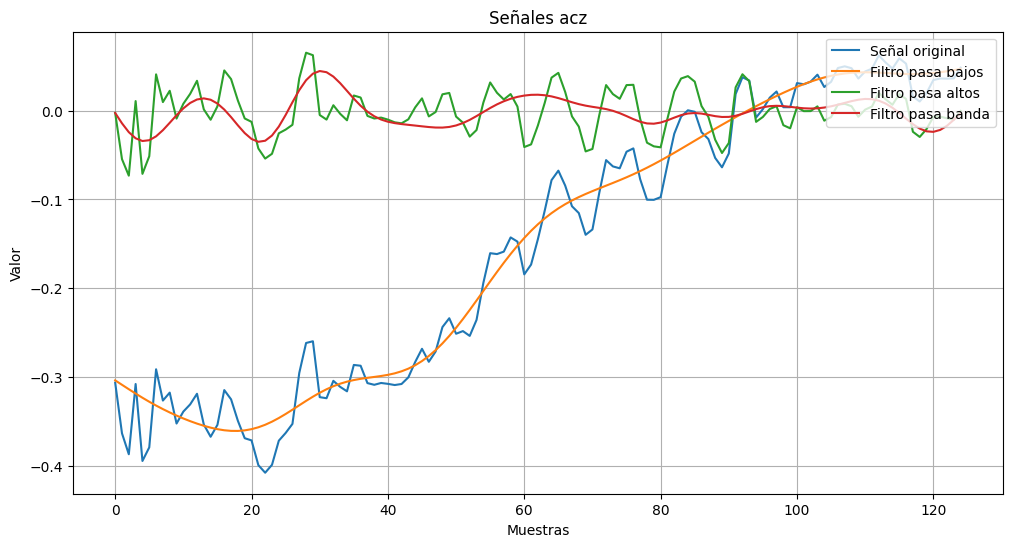

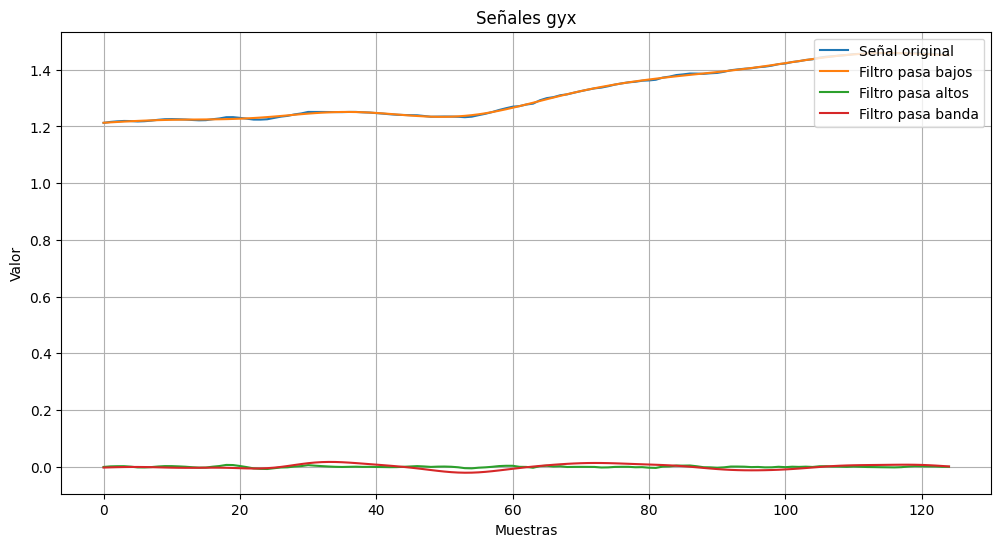

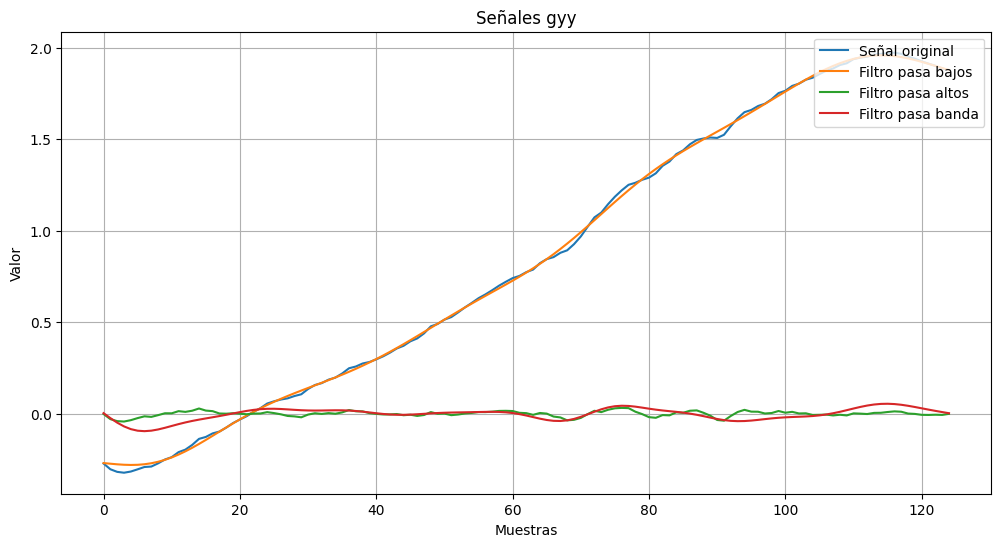

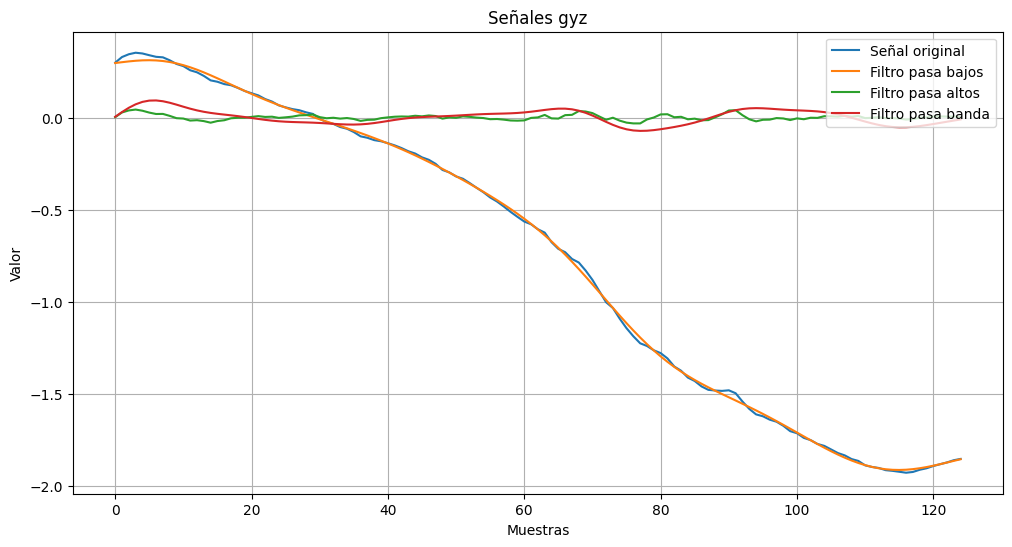

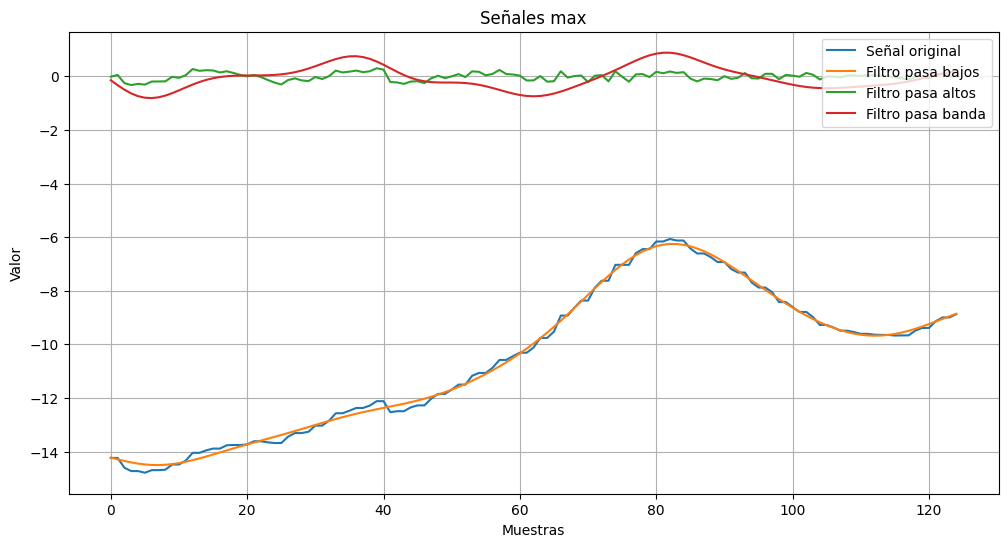

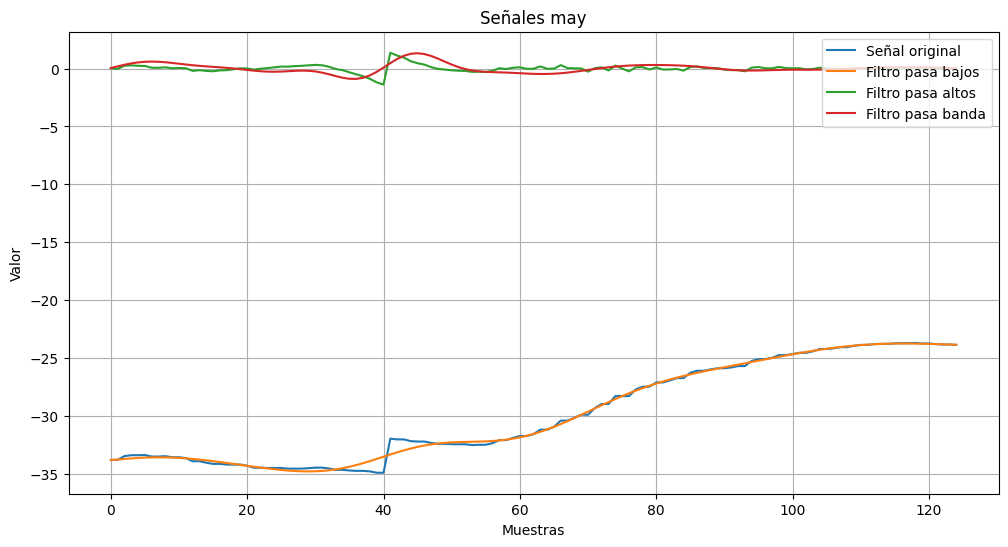

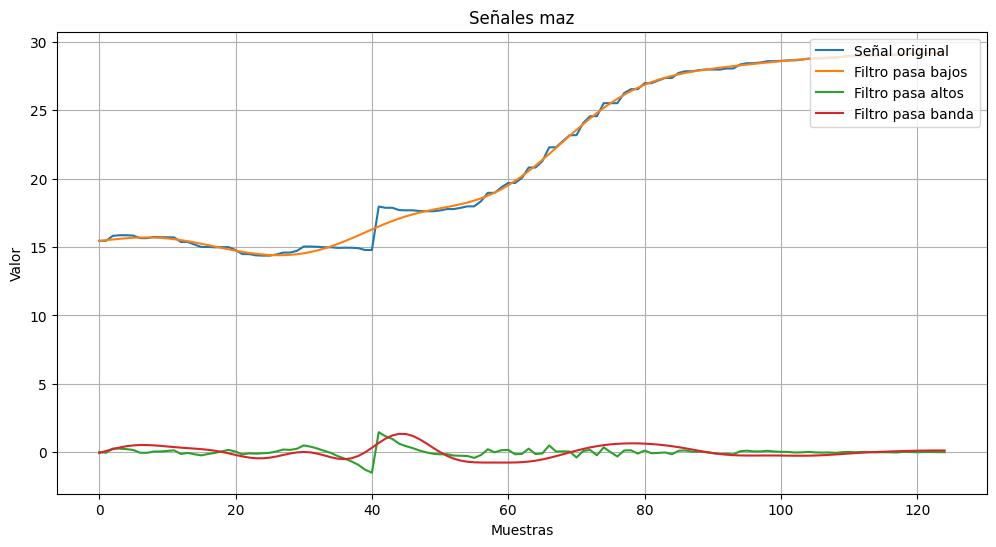

In [10]:
cutoff = 2.5
lowcut = 1.0
highcut = 5.0
fs = 60.0

def low_pass_filter(data, cutoff, fs, order=5):
    nyquist = 0.5 * fs
    normal_cutoff = cutoff / nyquist
    b, a = butter(order, normal_cutoff, btype='low', analog=False)
    y = filtfilt(b, a, data)
    return y

def high_pass_filter(data, cutoff, fs, order=5):
    nyquist = 0.5 * fs
    normal_cutoff = cutoff / nyquist
    b, a = butter(order, normal_cutoff, btype='high', analog=False)
    y = filtfilt(b, a, data)
    return y

def band_pass_filter(data, lowcut, highcut, fs, order=5):
    nyquist = 0.5 * fs
    low = lowcut / nyquist
    high = highcut / nyquist
    b, a = butter(order, [low, high], btype='band')
    y = filtfilt(b, a, data)
    return y

def signals(i, df, IMU):
  samples = np.arange(0, 125, 1)
  X_features = [col for col in df.columns if col.startswith(f'{IMU}x')]
  Y_features = [col for col in df.columns if col.startswith(f'{IMU}y')]
  Z_features = [col for col in df.columns if col.startswith(f'{IMU}z')]
  i_row_IMUx = df[X_features].iloc[i]
  i_row_IMUy = df[Y_features].iloc[i]
  i_row_IMUz = df[Z_features].iloc[i]

  low_passx = low_pass_filter(i_row_IMUx, cutoff, fs)
  high_passx = high_pass_filter(i_row_IMUx, cutoff, fs)
  band_passx = band_pass_filter(i_row_IMUx, lowcut, highcut, fs)
  low_passy = low_pass_filter(i_row_IMUy, cutoff, fs)
  high_passy = high_pass_filter(i_row_IMUy, cutoff, fs)
  band_passy = band_pass_filter(i_row_IMUy, lowcut, highcut, fs)
  low_passz = low_pass_filter(i_row_IMUz, cutoff, fs)
  high_passz = high_pass_filter(i_row_IMUz, cutoff, fs)
  band_passz = band_pass_filter(i_row_IMUz, lowcut, highcut, fs)

  plt.figure(figsize=(12, 6))
  plt.plot(samples, i_row_IMUx)
  plt.plot(samples, low_passx)
  plt.plot(samples, high_passx)
  plt.plot(samples, band_passx)
  plt.title(f'Señales {IMU}x')
  plt.xlabel('Muestras')
  plt.ylabel('Valor')
  plt.legend(['Señal original', 'Filtro pasa bajos', 'Filtro pasa altos', 'Filtro pasa banda'], loc='upper right')
  plt.grid(True)
  plt.show()

  plt.figure(figsize=(12, 6))
  plt.plot(samples, i_row_IMUy)
  plt.plot(samples, low_passy)
  plt.plot(samples, high_passy)
  plt.plot(samples, band_passy)
  plt.title(f'Señales {IMU}y')
  plt.xlabel('Muestras')
  plt.ylabel('Valor')
  plt.legend(['Señal original', 'Filtro pasa bajos', 'Filtro pasa altos', 'Filtro pasa banda'], loc='upper right')
  plt.grid(True)
  plt.show()

  plt.figure(figsize=(12, 6))
  plt.plot(samples, i_row_IMUz)
  plt.plot(samples, low_passz)
  plt.plot(samples, high_passz)
  plt.plot(samples, band_passz)
  plt.title(f'Señales {IMU}z')
  plt.xlabel('Muestras')
  plt.ylabel('Valor')
  plt.legend(['Señal original', 'Filtro pasa bajos', 'Filtro pasa altos', 'Filtro pasa banda'], loc='upper right')
  plt.grid(True)
  plt.show()


signals(0, first_class_occurrences, 'ac')
signals(0, first_class_occurrences, 'gy')
signals(0, first_class_occurrences, 'ma')
# print('\n')
# signals(1, first_class_occurrences, 'ac')
# signals(1, first_class_occurrences, 'gy')
# signals(1, first_class_occurrences, 'ma')
# print('\n')
# signals(2, first_class_occurrences, 'ac')
# signals(2, first_class_occurrences, 'gy')
# signals(2, first_class_occurrences, 'ma')
# print('\n')
# signals(3, first_class_occurrences, 'ac')
# signals(3, first_class_occurrences, 'gy')
# signals(3, first_class_occurrences, 'ma')
# print('\n')
# signals(4, first_class_occurrences, 'ac')
# signals(4, first_class_occurrences, 'gy')
# signals(4, first_class_occurrences, 'ma')
# print('\n')
# signals(5, first_class_occurrences, 'ac')
# signals(5, first_class_occurrences, 'gy')
# signals(5, first_class_occurrences, 'ma')
# print('\n')
# signals(6, first_class_occurrences, 'ac')
# signals(6, first_class_occurrences, 'gy')
# signals(6, first_class_occurrences, 'ma')
# print('\n')
# signals(7, first_class_occurrences, 'ac')
# signals(7, first_class_occurrences, 'gy')
# signals(7, first_class_occurrences, 'ma')

A partir de los gráficos anteriores se vislumbra que la mejor opción es utlizar el filtro pasabajos, pues mantiene la forma de la señal original eliminando el ruido perjudicial.

In [11]:
def apply_low_pass_filter(df, cutoff, fs):
    filtered_df = df.copy()
    X_ac_features = [col for col in df.columns if col.startswith('acx')]
    Y_ac_features = [col for col in df.columns if col.startswith('acy')]
    Z_ac_features = [col for col in df.columns if col.startswith('acz')]
    X_gy_features = [col for col in df.columns if col.startswith('gyx')]
    Y_gy_features = [col for col in df.columns if col.startswith('gyy')]
    Z_gy_features = [col for col in df.columns if col.startswith('gyz')]
    X_ma_features = [col for col in df.columns if col.startswith('max')]
    Y_ma_features = [col for col in df.columns if col.startswith('may')]
    Z_ma_features = [col for col in df.columns if col.startswith('maz')]

    for i in range(len(df)):
      row_acx = filtered_df[X_ac_features].iloc[i].values
      row_acy = filtered_df[Y_ac_features].iloc[i].values
      row_acz = filtered_df[Z_ac_features].iloc[i].values
      row_gyx = filtered_df[X_gy_features].iloc[i].values
      row_gyy = filtered_df[Y_gy_features].iloc[i].values
      row_gyz = filtered_df[Z_gy_features].iloc[i].values
      row_max = filtered_df[X_ma_features].iloc[i].values
      row_may = filtered_df[Y_ma_features].iloc[i].values
      row_maz = filtered_df[Z_ma_features].iloc[i].values

      row = []
      low_pass_ac_x = low_pass_filter(row_acx, cutoff, fs)
      low_pass_ac_y = low_pass_filter(row_acy, cutoff, fs)
      low_pass_ac_z = low_pass_filter(row_acz, cutoff, fs)
      low_pass_gy_x = low_pass_filter(row_gyx, cutoff, fs)
      low_pass_gy_y = low_pass_filter(row_gyy, cutoff, fs)
      low_pass_gy_z = low_pass_filter(row_gyz, cutoff, fs)
      low_pass_ma_x = low_pass_filter(row_max, cutoff, fs)
      low_pass_ma_y = low_pass_filter(row_may, cutoff, fs)
      low_pass_ma_z = low_pass_filter(row_maz, cutoff, fs)

      row.extend(low_pass_ac_x)
      row.extend(low_pass_ac_y)
      row.extend(low_pass_ac_z)
      row.extend(low_pass_gy_x)
      row.extend(low_pass_gy_y)
      row.extend(low_pass_gy_z)
      row.extend(low_pass_ma_x)
      row.extend(low_pass_ma_y)
      row.extend(low_pass_ma_z)

      filtered_df.iloc[i, 1:1227] = row

    return filtered_df

In [36]:
filtered_X_train = apply_low_pass_filter(X_train, cutoff, fs)
filtered_X_val = apply_low_pass_filter(X_val, cutoff, fs)

# Características utilizadas

In [37]:
def calculate_features(sequence):
    features = {}
    features['mean'] = np.mean(sequence)
    features['variance'] = np.var(sequence)
    features['min'] = np.min(sequence)
    features['max'] = np.max(sequence)
    features['rms'] = np.sqrt(np.mean(sequence**2))
    features['skew'] = skew(sequence)
    features['kurtosis'] = kurtosis(sequence)
    features['correlation'] = np.correlate(sequence, sequence, mode='full')[len(sequence)-1] / len(sequence)
    hist, _ = np.histogram(sequence, bins=10, density=True)
    hist = hist[hist > 0]
    features['average_entropy'] =  -np.sum(hist * np.log(hist))
    return features

In [38]:
def extract_features_for_sensors(df):
    feature_dict = {}
    sensors = ['acx', 'acy', 'acz', 'gyx', 'gyy', 'gyz', 'max', 'may', 'maz']
    for sensor in sensors:
        columns = [f"{sensor}{i}" for i in range(125)]
        sequence = df[columns].values
        features = calculate_features(sequence)
        feature_dict.update({f"{sensor}_{k}": v for k, v in features.items()})
    return pd.Series(feature_dict)

In [39]:
features_train = filtered_X_train.apply(extract_features_for_sensors, axis=1)
features_val = filtered_X_val.apply(extract_features_for_sensors, axis=1)

In [40]:
Scaler = StandardScaler()
Scaler.fit(features_train)
features_train_normalized = Scaler.transform(features_train)
features_val_normalized = Scaler.transform(features_val)
df_train_normalized = pd.DataFrame(features_train_normalized, columns=features_train.columns)
df_val_normalized = pd.DataFrame(features_val_normalized, columns=features_val.columns)
df_train_normalized.index = filtered_X_train.index
df_val_normalized.index = filtered_X_val.index

# Selección de características

In [19]:
selector = SelectKBest(score_func=f_classif, k=int(len(df_train_normalized.columns) * 0.5))
reduced_train = selector.fit_transform(df_train_normalized, y_train)
reduced_val = selector.fit_transform(df_val_normalized, y_val)

# Clasificadores y resultados en validación

## Definición del split

In [20]:
indexs = np.zeros(len(df_train_normalized) + len(df_val_normalized))
indexs[:len(df_train_normalized)] = -1
cv = PredefinedSplit(test_fold=indexs)

## Modelo Random Forest

Tiempo de entrenamiento: 90.94453239440918 segundos
Mejor Clasificador: RandomForestClassifier (max_depth=15, n_estimators=200)
Accuracy: 0.88
              precision    recall  f1-score   support

           1       0.93      0.50      0.65       160
           2       0.59      0.96      0.73       160
           3       1.00      0.78      0.88       144
           4       1.00      0.88      0.94       160
           5       0.95      0.96      0.95       160
           6       0.96      1.00      0.98       160
           7       0.93      0.94      0.93       160
           8       0.90      0.99      0.95       160

    accuracy                           0.88      1264
   macro avg       0.91      0.88      0.88      1264
weighted avg       0.91      0.88      0.88      1264



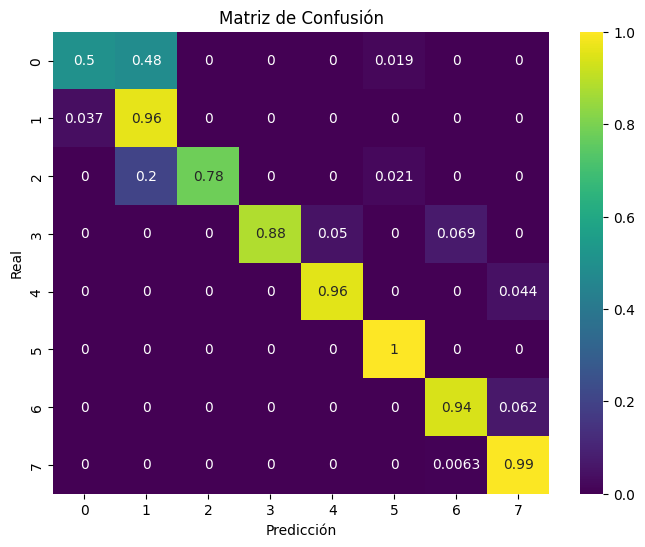

Tiempo de entrenamiento: 59.9380259513855 segundos
Mejor Clasificador: RandomForestClassifier (max_depth=10, n_estimators=100)
Accuracy: 0.68
              precision    recall  f1-score   support

           1       0.70      0.44      0.54       160
           2       0.61      0.88      0.72       160
           3       1.00      0.65      0.79       144
           4       1.00      0.84      0.92       160
           5       0.81      0.71      0.76       160
           6       0.43      1.00      0.60       160
           7       0.72      0.30      0.42       160
           8       0.77      0.62      0.69       160

    accuracy                           0.68      1264
   macro avg       0.76      0.68      0.68      1264
weighted avg       0.75      0.68      0.68      1264



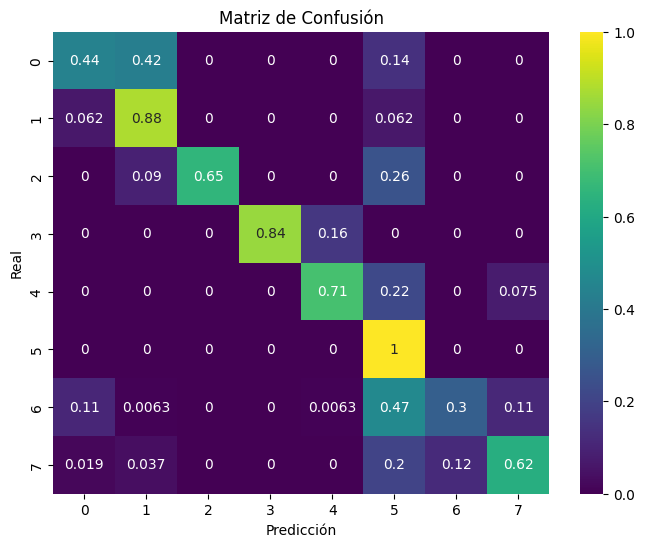

In [21]:
rf_model = RandomForestClassifier(random_state=3)
parameters_grid_rf = {'max_depth':[10, 15, 20, 25, 30],'n_estimators': [50, 100, 150, 200, 250]}
grid_search_rf = GridSearchCV(rf_model, param_grid=parameters_grid_rf, cv=cv)
start = time.time()
grid_search_rf.fit(np.vstack((df_train_normalized, df_val_normalized)), np.hstack((y_train, y_val)))
end = time.time()
best_rf = grid_search_rf.best_estimator_
print(f'Tiempo de entrenamiento: {end - start} segundos')
print(f'Mejor Clasificador: RandomForestClassifier (max_depth={best_rf.max_depth}, n_estimators={best_rf.n_estimators})')
best_rf.fit(df_train_normalized, y_train)
y_pred = best_rf.predict(df_val_normalized)
accuracy = accuracy_score(y_pred, y_val)
print(f'Accuracy: {accuracy:.2f}')
print(classification_report(y_val, y_pred))
plt.figure(figsize=(8,6))
sns.heatmap(confusion_matrix(y_val, y_pred, normalize='true'), annot=True, cmap=plt.cm.viridis)
plt.title('Matriz de Confusión')
plt.xlabel('Predicción')
plt.ylabel('Real')
plt.show()

grid_search_rf_k_best = GridSearchCV(rf_model, param_grid=parameters_grid_rf, cv=cv)
start = time.time()
grid_search_rf_k_best.fit(np.vstack((reduced_train, reduced_val)), np.hstack((y_train, y_val)))
end = time.time()
best_rf_k_best = grid_search_rf_k_best.best_estimator_
print(f'Tiempo de entrenamiento: {end - start} segundos')
print(f'Mejor Clasificador: RandomForestClassifier (max_depth={best_rf_k_best.max_depth}, n_estimators={best_rf_k_best.n_estimators})')
best_rf_k_best.fit(reduced_train, y_train)
y_pred = best_rf_k_best.predict(reduced_val)
accuracy = accuracy_score(y_pred, y_val)
print(f'Accuracy: {accuracy:.2f}')
print(classification_report(y_val, y_pred))
plt.figure(figsize=(8,6))
sns.heatmap(confusion_matrix(y_val, y_pred, normalize='true'), annot=True, cmap=plt.cm.viridis)
plt.title('Matriz de Confusión')
plt.xlabel('Predicción')
plt.ylabel('Real')
plt.show()

## Modelos SVM

### Modelo SVM Lineal

Tiempo de entrenamiento: 0.7912979125976562 segundos
Mejor SVM: SVC(C=1, kernel='linear', random_state=3)
Accuracy: 0.84
              precision    recall  f1-score   support

           1       0.87      0.50      0.63       160
           2       0.56      0.90      0.69       160
           3       1.00      0.78      0.88       144
           4       1.00      1.00      1.00       160
           5       0.97      1.00      0.98       160
           6       0.99      1.00      1.00       160
           7       0.96      0.59      0.73       160
           8       0.71      0.98      0.83       160

    accuracy                           0.84      1264
   macro avg       0.88      0.84      0.84      1264
weighted avg       0.88      0.84      0.84      1264



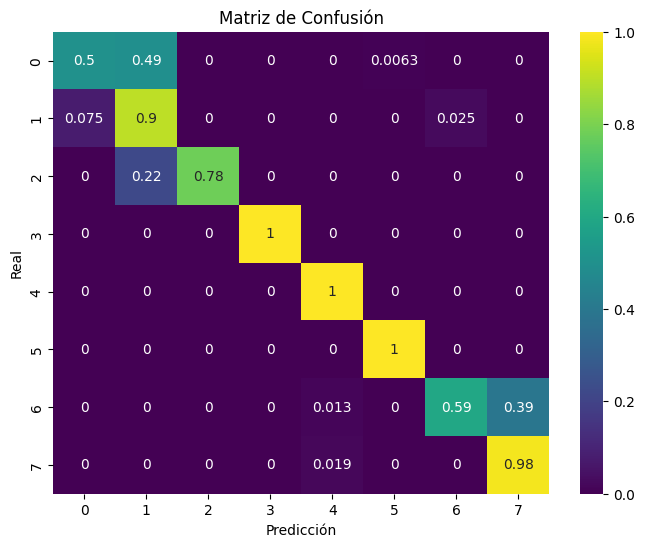

Tiempo de entrenamiento: 0.6228890419006348 segundos
Mejor SVM: SVC(C=0.01, kernel='linear', random_state=3)
Accuracy: 0.75
              precision    recall  f1-score   support

           1       0.42      0.73      0.53       160
           2       0.56      0.70      0.62       160
           3       0.99      0.78      0.87       144
           4       1.00      0.99      1.00       160
           5       0.92      0.98      0.95       160
           6       0.99      0.91      0.95       160
           7       0.66      0.34      0.45       160
           8       0.76      0.54      0.63       160

    accuracy                           0.75      1264
   macro avg       0.79      0.75      0.75      1264
weighted avg       0.78      0.75      0.75      1264



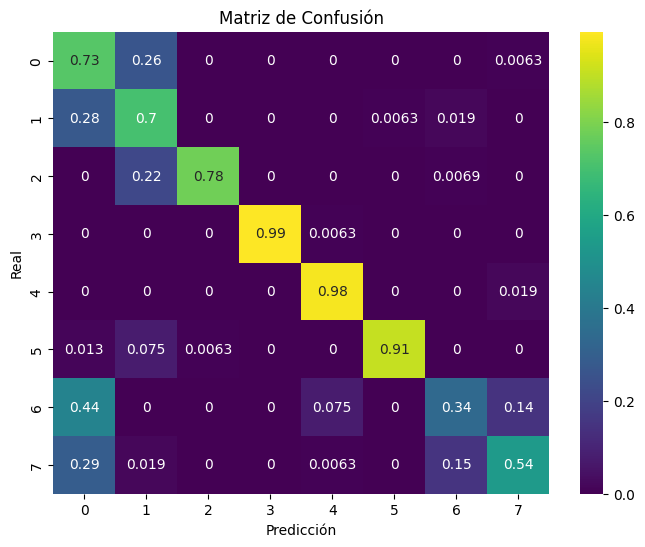

In [22]:
svm_linear_model = SVC(kernel= 'linear', random_state=3)
parameters_grid_svm = {'C': [0.01, 0.1, 1, 10, 100]}
grid_search_svm = GridSearchCV(svm_linear_model, param_grid=parameters_grid_svm, cv=cv)
start = time.time()
grid_search_svm.fit(np.vstack((df_train_normalized, df_val_normalized)), np.hstack((y_train, y_val)))
end = time.time()
best_linear_svm = grid_search_svm.best_estimator_
print(f'Tiempo de entrenamiento: {end - start} segundos')
print(f'Mejor SVM: {best_linear_svm}')
best_linear_svm.fit(df_train_normalized, y_train)
y_pred = best_linear_svm.predict(df_val_normalized)
accuracy = accuracy_score(y_pred, y_val)
print(f'Accuracy: {accuracy:.2f}')
print(classification_report(y_val, y_pred))
plt.figure(figsize=(8,6))
sns.heatmap(confusion_matrix(y_val, y_pred, normalize='true'), annot=True, cmap=plt.cm.viridis)
plt.title('Matriz de Confusión')
plt.xlabel('Predicción')
plt.ylabel('Real')
plt.show()

grid_search_svm_k_best = GridSearchCV(svm_linear_model, param_grid=parameters_grid_svm, cv=cv)
start = time.time()
grid_search_svm_k_best.fit(np.vstack((reduced_train, reduced_val)), np.hstack((y_train, y_val)))
end = time.time()
best_linear_svm_k_best = grid_search_svm_k_best.best_estimator_
print(f'Tiempo de entrenamiento: {end - start} segundos')
print(f'Mejor SVM: {best_linear_svm_k_best}')
best_linear_svm_k_best.fit(reduced_train, y_train)
y_pred = best_linear_svm_k_best.predict(reduced_val)
accuracy = accuracy_score(y_pred, y_val)
print(f'Accuracy: {accuracy:.2f}')
print(classification_report(y_val, y_pred))
plt.figure(figsize=(8,6))
sns.heatmap(confusion_matrix(y_val, y_pred, normalize='true'), annot=True, cmap=plt.cm.viridis)
plt.title('Matriz de Confusión')
plt.xlabel('Predicción')
plt.ylabel('Real')
plt.show()

### Modelo SVM Polinomial

Tiempo de entrenamiento: 15.552610635757446 segundos
Mejor SVM: SVC(C=0.01, coef0=5, degree=2, kernel='poly', random_state=3)
Accuracy: 0.92
              precision    recall  f1-score   support

           1       0.99      0.76      0.86       160
           2       0.65      0.99      0.79       160
           3       1.00      0.78      0.88       144
           4       1.00      1.00      1.00       160
           5       0.97      1.00      0.98       160
           6       1.00      0.97      0.99       160
           7       0.99      0.93      0.95       160
           8       0.93      0.89      0.91       160

    accuracy                           0.92      1264
   macro avg       0.94      0.92      0.92      1264
weighted avg       0.94      0.92      0.92      1264



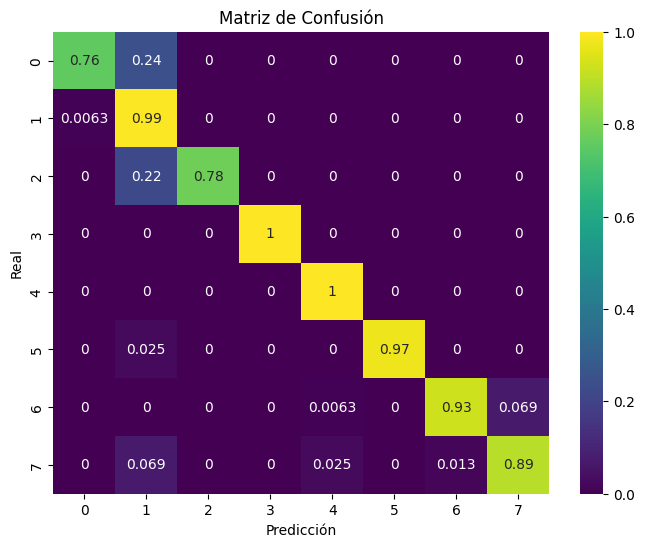

Tiempo de entrenamiento: 11.792775630950928 segundos
Mejor SVM: SVC(C=0.01, coef0=20, degree=2, kernel='poly', random_state=3)
Accuracy: 0.75
              precision    recall  f1-score   support

           1       0.43      0.73      0.54       160
           2       0.56      0.71      0.62       160
           3       0.99      0.78      0.87       144
           4       1.00      0.99      1.00       160
           5       0.92      0.98      0.95       160
           6       0.99      0.91      0.95       160
           7       0.67      0.35      0.46       160
           8       0.77      0.55      0.64       160

    accuracy                           0.75      1264
   macro avg       0.79      0.75      0.75      1264
weighted avg       0.79      0.75      0.75      1264



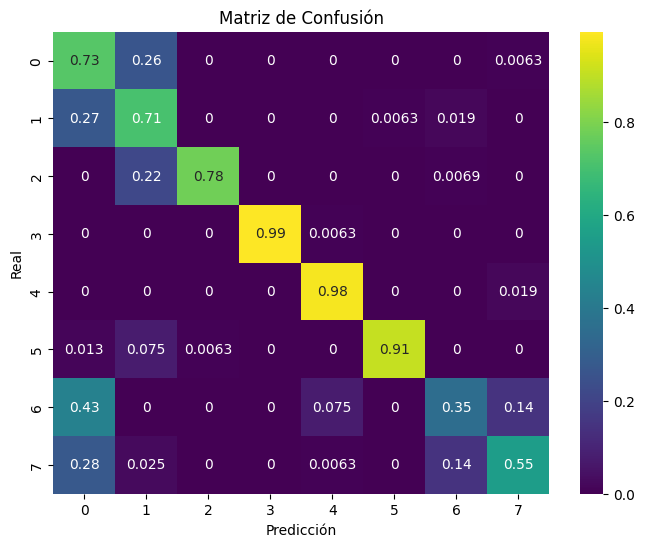

In [44]:
svm_poly_model = SVC(kernel='poly', random_state=3)
parameters_grid_svm = {'C': [0.01, 0.1, 1, 10], 'degree': [2, 3, 4, 5], 'coef0': [1, 5, 10, 20]}
grid_search_svm = GridSearchCV(svm_poly_model, param_grid=parameters_grid_svm, cv=cv)
start = time.time()
grid_search_svm.fit(np.vstack((df_train_normalized, df_val_normalized)), np.hstack((y_train, y_val)))
end = time.time()
best_poly_svm = grid_search_svm.best_estimator_
print(f'Tiempo de entrenamiento: {end - start} segundos')
print(f'Mejor SVM: {best_poly_svm}')
best_poly_svm.fit(df_train_normalized, y_train)
y_pred = best_poly_svm.predict(df_val_normalized)
accuracy = accuracy_score(y_pred, y_val)
print(f'Accuracy: {accuracy:.2f}')
print(classification_report(y_val, y_pred))
plt.figure(figsize=(8,6))
sns.heatmap(confusion_matrix(y_val, y_pred, normalize='true'), annot=True, cmap=plt.cm.viridis)
plt.title('Matriz de Confusión')
plt.xlabel('Predicción')
plt.ylabel('Real')
plt.show()

grid_search_poly_svm_k_best = GridSearchCV(svm_poly_model, param_grid=parameters_grid_svm, cv=cv)
start = time.time()
grid_search_poly_svm_k_best.fit(np.vstack((reduced_train, reduced_val)), np.hstack((y_train, y_val)))
end = time.time()
best_poly_svm_k_best = grid_search_poly_svm_k_best.best_estimator_
print(f'Tiempo de entrenamiento: {end - start} segundos')
print(f'Mejor SVM: {best_poly_svm_k_best}')
best_poly_svm_k_best.fit(reduced_train, y_train)
y_pred = best_poly_svm_k_best.predict(reduced_val)
accuracy = accuracy_score(y_pred, y_val)
print(f'Accuracy: {accuracy:.2f}')
print(classification_report(y_val, y_pred))
plt.figure(figsize=(8,6))
sns.heatmap(confusion_matrix(y_val, y_pred, normalize='true'), annot=True, cmap=plt.cm.viridis)
plt.title('Matriz de Confusión')
plt.xlabel('Predicción')
plt.ylabel('Real')
plt.show()

### Modelo SVM Gaussiano

Tiempo de entrenamiento: 13.931703090667725 segundos
Mejor SVM: SVC(C=1, gamma=0.001, random_state=3)
Accuracy: 0.92
              precision    recall  f1-score   support

           1       0.99      0.72      0.83       160
           2       0.66      1.00      0.79       160
           3       1.00      0.78      0.88       144
           4       1.00      1.00      1.00       160
           5       0.97      0.99      0.98       160
           6       1.00      0.99      1.00       160
           7       1.00      0.91      0.95       160
           8       0.91      0.94      0.93       160

    accuracy                           0.92      1264
   macro avg       0.94      0.92      0.92      1264
weighted avg       0.94      0.92      0.92      1264



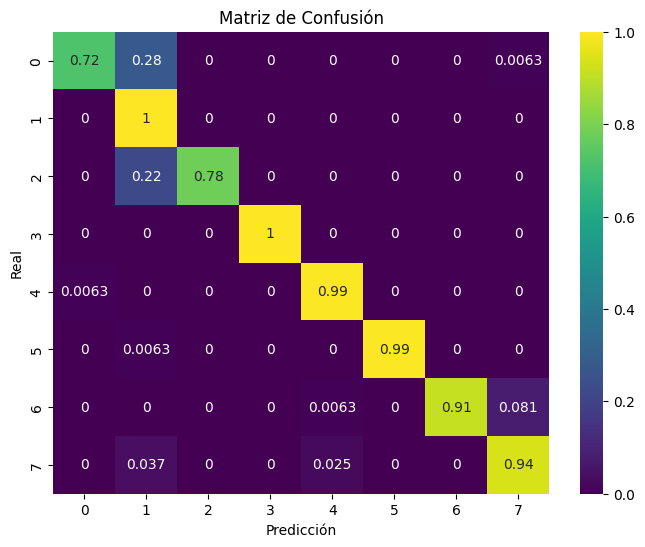

Tiempo de entrenamiento: 4.867945432662964 segundos
Mejor SVM: SVC(C=10, gamma=0.001, random_state=3)
Accuracy: 0.75
              precision    recall  f1-score   support

           1       0.42      0.74      0.54       160
           2       0.58      0.72      0.64       160
           3       1.00      0.78      0.88       144
           4       1.00      0.99      0.99       160
           5       0.93      0.98      0.95       160
           6       0.97      0.92      0.95       160
           7       0.67      0.36      0.47       160
           8       0.73      0.49      0.58       160

    accuracy                           0.75      1264
   macro avg       0.79      0.75      0.75      1264
weighted avg       0.78      0.75      0.75      1264



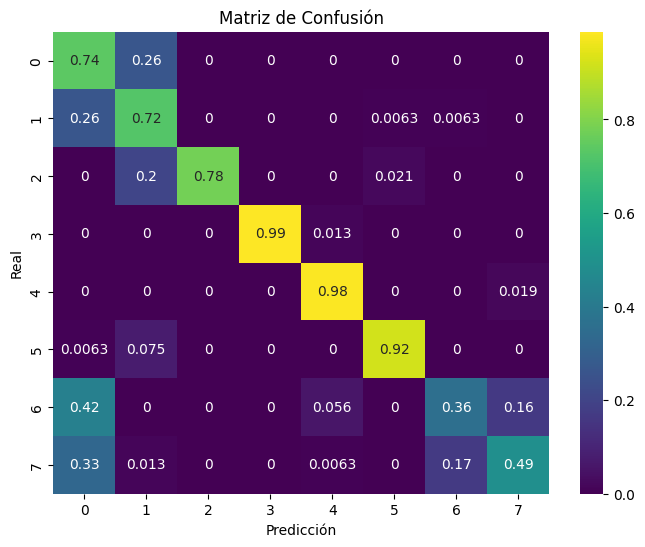

In [26]:
svm_rbf_model = SVC(kernel='rbf', random_state=3)
parameters_grid_svm = {'C': [0.1, 1, 10, 100], 'gamma': [0.001, 0.01, 0.1]}
grid_search_svm = GridSearchCV(svm_rbf_model, param_grid=parameters_grid_svm, cv=cv)
start = time.time()
grid_search_svm.fit(np.vstack((df_train_normalized, df_val_normalized)), np.hstack((y_train, y_val)))
end = time.time()
best_rbf_svm = grid_search_svm.best_estimator_
print(f'Tiempo de entrenamiento: {end - start} segundos')
print(f'Mejor SVM: {best_rbf_svm}')
best_rbf_svm.fit(df_train_normalized, y_train)
y_pred = best_rbf_svm.predict(df_val_normalized)
accuracy = accuracy_score(y_pred, y_val)
print(f'Accuracy: {accuracy:.2f}')
print(classification_report(y_val, y_pred))
plt.figure(figsize=(8,6))
sns.heatmap(confusion_matrix(y_val, y_pred, normalize='true'), annot=True, cmap=plt.cm.viridis)
plt.title('Matriz de Confusión')
plt.xlabel('Predicción')
plt.ylabel('Real')
plt.show()

grid_search_svm_k_best = GridSearchCV(svm_rbf_model, param_grid=parameters_grid_svm, cv=cv)
start = time.time()
grid_search_svm_k_best.fit(np.vstack((reduced_train, reduced_val)), np.hstack((y_train, y_val)))
end = time.time()
best_rbf_svm_k_best = grid_search_svm_k_best.best_estimator_
print(f'Tiempo de entrenamiento: {end - start} segundos')
print(f'Mejor SVM: {best_rbf_svm_k_best}')
best_rbf_svm_k_best.fit(reduced_train, y_train)
y_pred = best_rbf_svm_k_best.predict(reduced_val)
accuracy = accuracy_score(y_pred, y_val)
print(f'Accuracy: {accuracy:.2f}')
print(classification_report(y_val, y_pred))
plt.figure(figsize=(8,6))
sns.heatmap(confusion_matrix(y_val, y_pred, normalize='true'), annot=True, cmap=plt.cm.viridis)
plt.title('Matriz de Confusión')
plt.xlabel('Predicción')
plt.ylabel('Real')
plt.show()

### Modelo SVM Sigmoide

Tiempo de entrenamiento: 67.60759925842285 segundos
Mejor SVM: SVC(C=1, coef0=0.01, gamma=0.001, kernel='sigmoid', random_state=3)
Accuracy: 0.91
              precision    recall  f1-score   support

           1       0.99      0.76      0.86       160
           2       0.63      0.99      0.77       160
           3       1.00      0.78      0.88       144
           4       1.00      0.99      0.99       160
           5       0.96      0.99      0.98       160
           6       1.00      0.97      0.98       160
           7       0.96      0.95      0.96       160
           8       0.95      0.86      0.90       160

    accuracy                           0.91      1264
   macro avg       0.94      0.91      0.91      1264
weighted avg       0.94      0.91      0.92      1264



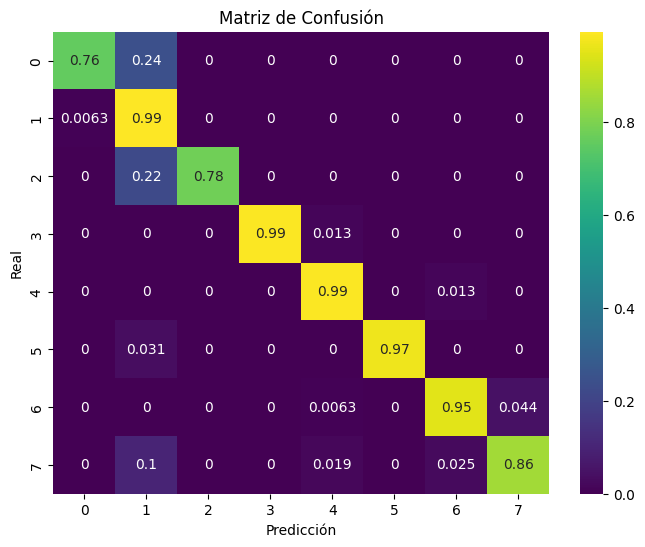

Tiempo de entrenamiento: 75.36502695083618 segundos
Mejor SVM: SVC(C=100, coef0=0.1, gamma=0.01, kernel='sigmoid', random_state=3)
Accuracy: 0.79
              precision    recall  f1-score   support

           1       0.48      0.95      0.64       160
           2       0.86      0.76      0.81       160
           3       0.99      0.78      0.87       144
           4       1.00      0.93      0.96       160
           5       0.86      0.99      0.92       160
           6       0.97      0.88      0.92       160
           7       0.80      0.44      0.56       160
           8       0.74      0.60      0.66       160

    accuracy                           0.79      1264
   macro avg       0.84      0.79      0.79      1264
weighted avg       0.84      0.79      0.79      1264



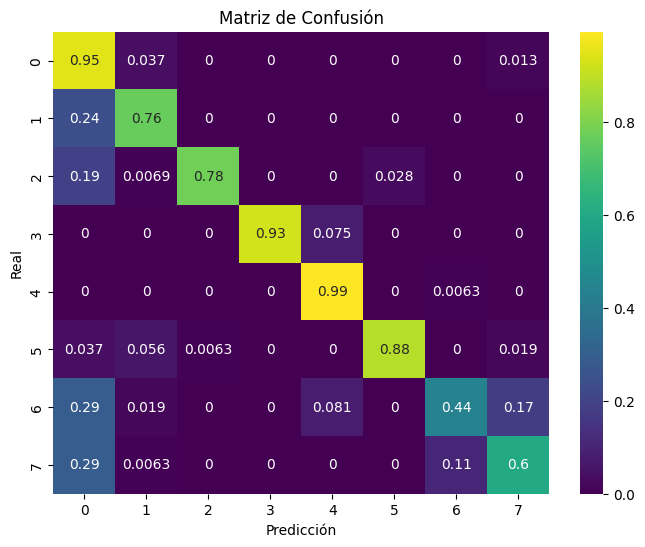

In [25]:
svm_sigmoid_model = SVC(kernel='sigmoid', random_state=3)
parameters_grid_svm = {'C': [0.1, 1, 10, 100], 'gamma': [0.001, 0.01, 0.1, 1], 'coef0': [0.01, 0.1, 1, 10]}
grid_search_svm = GridSearchCV(svm_sigmoid_model, param_grid=parameters_grid_svm, cv=cv)
start = time.time()
grid_search_svm.fit(np.vstack((df_train_normalized, df_val_normalized)), np.hstack((y_train, y_val)))
end = time.time()
best_sigmoid_svm = grid_search_svm.best_estimator_
print(f'Tiempo de entrenamiento: {end - start} segundos')
print(f'Mejor SVM: {best_sigmoid_svm}')
best_sigmoid_svm.fit(df_train_normalized, y_train)
y_pred = best_sigmoid_svm.predict(df_val_normalized)
accuracy = accuracy_score(y_pred, y_val)
print(f'Accuracy: {accuracy:.2f}')
print(classification_report(y_val, y_pred))
plt.figure(figsize=(8,6))
sns.heatmap(confusion_matrix(y_val, y_pred, normalize='true'), annot=True, cmap=plt.cm.viridis)
plt.title('Matriz de Confusión')
plt.xlabel('Predicción')
plt.ylabel('Real')
plt.show()

grid_search_svm_k_best = GridSearchCV(svm_sigmoid_model, param_grid=parameters_grid_svm, cv=cv)
start = time.time()
grid_search_svm_k_best.fit(np.vstack((reduced_train, reduced_val)), np.hstack((y_train, y_val)))
end = time.time()
best_sigmoid_svm_k_best = grid_search_svm_k_best.best_estimator_
print(f'Tiempo de entrenamiento: {end - start} segundos')
print(f'Mejor SVM: {best_sigmoid_svm_k_best}')
best_sigmoid_svm_k_best.fit(reduced_train, y_train)
y_pred = best_sigmoid_svm_k_best.predict(reduced_val)
accuracy = accuracy_score(y_pred, y_val)
print(f'Accuracy: {accuracy:.2f}')
print(classification_report(y_val, y_pred))
plt.figure(figsize=(8,6))
sns.heatmap(confusion_matrix(y_val, y_pred, normalize='true'), annot=True, cmap=plt.cm.viridis)
plt.title('Matriz de Confusión')
plt.xlabel('Predicción')
plt.ylabel('Real')
plt.show()

## Modelo KNN

Tiempo de entrenamiento: 8.9115629196167 segundos
Mejor KNN: KNeighborsClassifier(metric='manhattan', n_neighbors=18)
Accuracy: 0.83
              precision    recall  f1-score   support

           1       0.85      0.84      0.85       160
           2       0.76      0.86      0.81       160
           3       1.00      0.78      0.88       144
           4       0.92      0.79      0.85       160
           5       0.86      0.84      0.85       160
           6       1.00      0.94      0.97       160
           7       0.72      0.90      0.80       160
           8       0.67      0.70      0.69       160

    accuracy                           0.83      1264
   macro avg       0.85      0.83      0.84      1264
weighted avg       0.85      0.83      0.84      1264



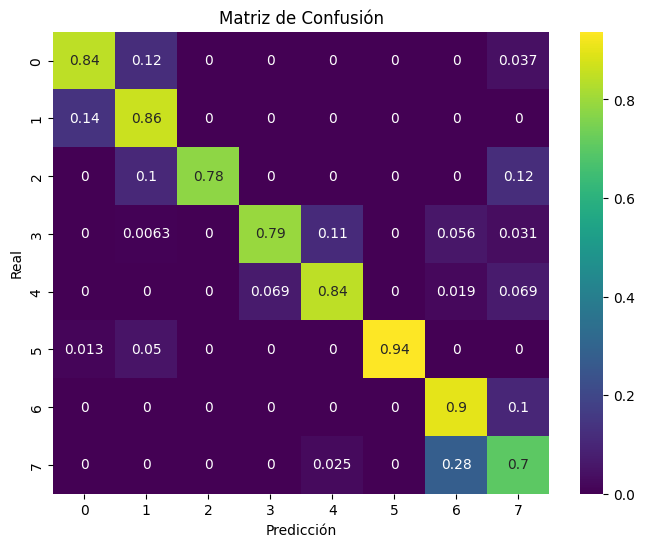

Tiempo de entrenamiento: 3.913578748703003 segundos
Mejor KNN: KNeighborsClassifier(metric='manhattan', n_neighbors=6, weights='distance')
Accuracy: 0.73
              precision    recall  f1-score   support

           1       0.48      0.53      0.50       160
           2       0.45      0.83      0.58       160
           3       1.00      0.78      0.88       144
           4       1.00      0.89      0.94       160
           5       0.78      0.96      0.86       160
           6       0.99      0.88      0.93       160
           7       0.73      0.49      0.58       160
           8       0.82      0.46      0.59       160

    accuracy                           0.73      1264
   macro avg       0.78      0.73      0.73      1264
weighted avg       0.78      0.73      0.73      1264



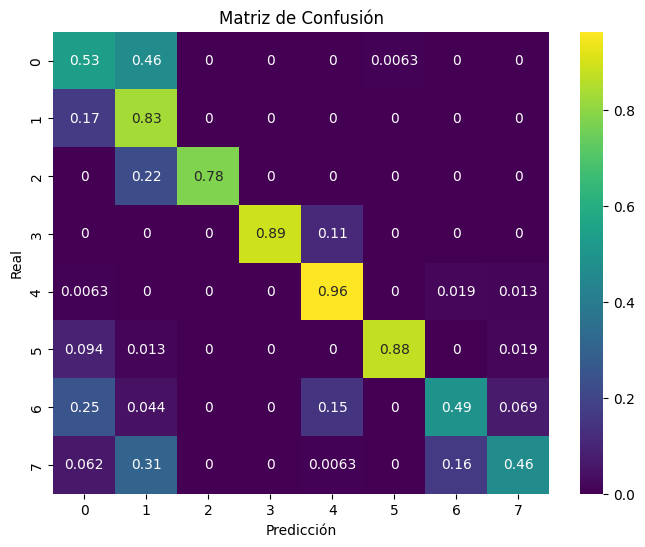

In [27]:
knn_model = KNeighborsClassifier()
parameters_grid_knn = {'n_neighbors': [6, 9, 12, 15, 18], 'weights': ['uniform', 'distance'],'metric': ['euclidean', 'manhattan', 'minkowski']}
grid_search_knn = GridSearchCV(knn_model, param_grid=parameters_grid_knn, cv=cv)
start = time.time()
grid_search_knn.fit(np.vstack((df_train_normalized, df_val_normalized)), np.hstack((y_train, y_val)))
end = time.time()
best_knn = grid_search_knn.best_estimator_
print(f'Tiempo de entrenamiento: {end - start} segundos')
print(f'Mejor KNN: {best_knn}')
best_knn.fit(df_train_normalized, y_train)
y_pred = best_knn.predict(df_val_normalized)
accuracy = accuracy_score(y_pred, y_val)
print(f'Accuracy: {accuracy:.2f}')
print(classification_report(y_val, y_pred))
plt.figure(figsize=(8,6))
sns.heatmap(confusion_matrix(y_val, y_pred, normalize='true'), annot=True, cmap=plt.cm.viridis)
plt.title('Matriz de Confusión')
plt.xlabel('Predicción')
plt.ylabel('Real')
plt.show()

grid_search_knn_k_best = GridSearchCV(knn_model, param_grid=parameters_grid_knn, cv=cv)
start = time.time()
grid_search_knn_k_best.fit(np.vstack((reduced_train, reduced_val)), np.hstack((y_train, y_val)))
end = time.time()
best_knn_k_best = grid_search_knn_k_best.best_estimator_
print(f'Tiempo de entrenamiento: {end - start} segundos')
print(f'Mejor KNN: {best_knn_k_best}')
best_knn_k_best.fit(reduced_train, y_train)
y_pred = best_knn_k_best.predict(reduced_val)
accuracy = accuracy_score(y_pred, y_val)
print(f'Accuracy: {accuracy:.2f}')
print(classification_report(y_val, y_pred))
plt.figure(figsize=(8,6))
sns.heatmap(confusion_matrix(y_val, y_pred, normalize='true'), annot=True, cmap=plt.cm.viridis)
plt.title('Matriz de Confusión')
plt.xlabel('Predicción')
plt.ylabel('Real')
plt.show()

## Modelo Naive Bayes

Tiempo de entrenamiento: 0.03250384330749512 segundos
Accuracy: 0.85
              precision    recall  f1-score   support

           1       0.94      0.86      0.90       160
           2       0.74      0.94      0.83       160
           3       1.00      0.78      0.88       144
           4       0.90      0.95      0.92       160
           5       0.78      0.89      0.83       160
           6       0.99      1.00      0.99       160
           7       1.00      0.41      0.58       160
           8       0.67      0.93      0.78       160

    accuracy                           0.85      1264
   macro avg       0.88      0.84      0.84      1264
weighted avg       0.87      0.85      0.84      1264



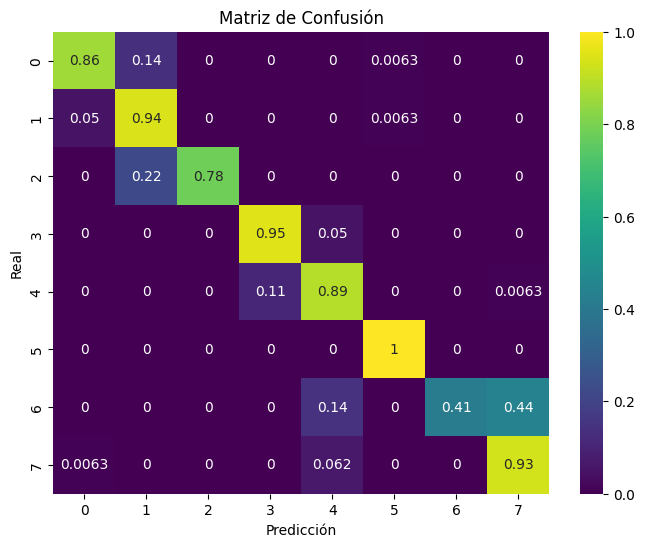

Tiempo de entrenamiento: 0.006201982498168945 segundos
Accuracy: 0.16
              precision    recall  f1-score   support

           1       0.00      0.00      0.00       160
           2       0.24      0.59      0.34       160
           3       0.13      0.78      0.23       144
           4       0.00      0.00      0.00       160
           5       0.00      0.00      0.00       160
           6       0.00      0.00      0.00       160
           7       0.00      0.00      0.00       160
           8       0.20      0.01      0.01       160

    accuracy                           0.16      1264
   macro avg       0.07      0.17      0.07      1264
weighted avg       0.07      0.16      0.07      1264



/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


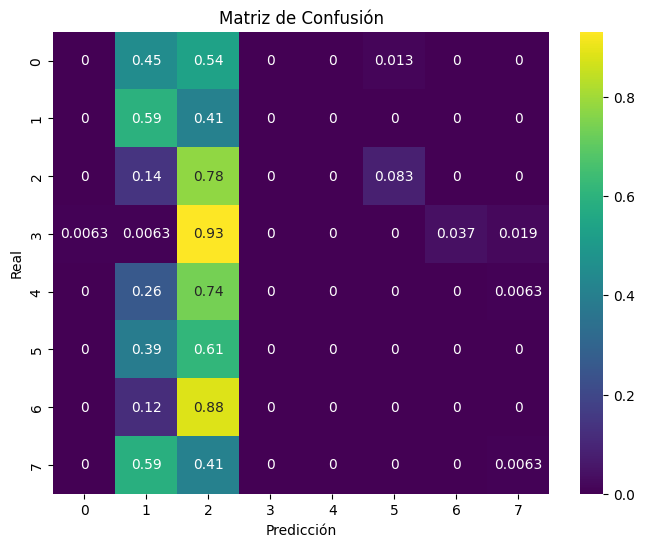

In [49]:
gnb = GaussianNB()
start = time.time()
gnb.fit(df_train_normalized, y_train)
end = time.time()
print(f'Tiempo de entrenamiento: {end - start} segundos')
y_pred = gnb.predict(df_val_normalized)
accuracy = accuracy_score(y_pred, y_val)
print(f'Accuracy: {accuracy:.2f}')
print(classification_report(y_val, y_pred))
plt.figure(figsize=(8,6))
sns.heatmap(confusion_matrix(y_val, y_pred, normalize='true'), annot=True, cmap=plt.cm.viridis)
plt.title('Matriz de Confusión')
plt.xlabel('Predicción')
plt.ylabel('Real')
plt.show()

start = time.time()
gnb.fit(reduced_train, y_train)
end = time.time()
print(f'Tiempo de entrenamiento: {end - start} segundos')
y_pred = gnb.predict(reduced_val)
accuracy = accuracy_score(y_pred, y_val)
print(f'Accuracy: {accuracy:.2f}')
print(classification_report(y_val, y_pred))
plt.figure(figsize=(8,6))
sns.heatmap(confusion_matrix(y_val, y_pred, normalize='true'), annot=True, cmap=plt.cm.viridis)
plt.title('Matriz de Confusión')
plt.xlabel('Predicción')
plt.ylabel('Real')
plt.show()

# Kaggle

In [30]:
filtered_test = apply_low_pass_filter(df_test, cutoff, fs)

In [31]:
features_test = filtered_test.apply(extract_features_for_sensors, axis=1)
features_test_normalized = Scaler.transform(features_test)
df_test_normalized = pd.DataFrame(features_test_normalized, columns=features_test.columns)
df_test.index = filtered_test.index

In [45]:
reduced_test = selector.transform(df_test_normalized)

In [46]:
labels_poly_svm = best_poly_svm.predict(df_test_normalized)
labels_rbf_svm = best_rbf_svm.predict(df_test_normalized)
labels_sigmoid_svm_k_best = y_pred = best_sigmoid_svm_k_best.predict(reduced_test)

In [47]:
labels_poly_df = pd.DataFrame({
    'Id': range(len(labels_poly_svm)),
    'Category': labels_poly_svm
})
labels_rbf_df = pd.DataFrame({
    'Id': range(len(labels_rbf_svm)),
    'Category': labels_rbf_svm
})
labels_sigmoid_k_best_df = pd.DataFrame({
    'Id': range(len(labels_sigmoid_svm_k_best)),
    'Category': labels_sigmoid_svm_k_best
})

In [48]:
labels_poly_df.to_csv('labels_poly_svm.csv', index=False)
labels_rbf_df.to_csv('labels_rbf_svm.csv', index=False)
labels_sigmoid_k_best_df.to_csv('labels_sigmoid_svm_k_best.csv', index=False)